<a href="https://colab.research.google.com/github/subhashraj3031/AlmaBetter_Project/blob/main/Integrated_Retail_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Integrated Retail Analytics for Store Optimization and Demand Forecasting

**Project type:** EDA, regression, time-series forecasting and unsupervised learning  

**Contribution:** Individual project

**Name:** Subhash Puri

**GitHub:** Not published.  


This notebook contains executable analysis code and completed explanations. The sections are adapted to the retail problem. Textual preprocessing and classification rebalancing do not apply. Raw data are treated as data, and text in the template is used only as a reporting reference.

## Project summary

This project studies how historical weekly retail sales can support store optimization, demand planning and more focused marketing. It brings together department-level sales, store characteristics and weekly contextual features. The objective is to turn those records into practical evidence: where unusual sales deserve investigation, how stores differ in their demand patterns, which forecasting methods generalize to later weeks, and which department relationships warrant a business experiment. The analysis focuses on existing stores and departments because the files do not contain individual customer identities or transaction baskets.

The first stage validates the data before modeling. Dates are parsed explicitly, source keys are checked for duplicates, holiday flags are reconciled and joins are required to preserve the sales grain. Missing markdown measures remain distinguishable from measured zeros. Negative sales are retained as possible returns rather than automatically removed. Source file hashes, missing-value counts and join checks make the preparation auditable. An anomaly review queue provides a separate place to investigate potential problems without silently rewriting the forecasting target.

Time is central to the design. Calendar features describe annual patterns and holiday weeks, while sales lags and trailing means use only earlier observations. External economic, climate and markdown measures are lagged one week so that target-week observations cannot leak into a forecast. Three expanding chronological validation windows select among last-week and annual seasonal baselines, regularized regression and histogram gradient boosting. The last thirteen weeks remain a separate test. Evaluation reports absolute error, squared-error sensitivity, proportional aggregate error and holiday-weighted error, because no single metric captures every planning concern.

The project also distinguishes weekly operational forecasting from forecasts made several weeks ahead. One-week evaluation can use the most recently observed sales. Fixed-origin forecasts must feed their own predictions into future lag features and use explicitly stated assumptions for unknown external variables. The notebook evaluates short recursive horizons and an annual seasonal planning baseline, then produces future forecast files relative to the historical dataset's end date. These products forecast sales value; actual inventory orders would additionally require units, prices, lead times, stockout information and service-level targets.

Store segmentation summarizes demand scale, variability, holiday behavior, markdown intensity, space efficiency and observed contextual conditions. K-means alternatives are compared with multiple separation and cohesion metrics, and repeated random initializations provide a limited stability check. PCA visualizes the resulting groups without replacing the full clustering feature space. These segments describe stores and can support differentiated replenishment reviews or campaign trials. They cannot justify individual shopper personalization.

Finally, department association analysis identifies co-elevated demand after accounting for typical store-department scale and common weekly movement. Support, confidence and lift are reported for training and later periods, with explicit joint-availability denominators. The findings are hypotheses for investigation, not evidence that customers purchased two products together. The final strategy connects measured forecasting errors, segment profiles and anomaly context to a phased retail pilot. It also states the limits of the available data, so that analytical results lead to realistic operating decisions rather than unsupported causal or commercial claims.

## Problem statement

Retail planners must balance availability against excess inventory while demand changes across stores, departments, promotions and seasons. Build and evaluate a reproducible system that forecasts weekly sales, highlights unusual records, groups stores for planning and proposes testable marketing actions. Evaluate on future dates and state what information is available at each prediction origin.


## 1. Know Your Data
### Import libraries and configure inputs
Run every cell in order. In Colab, upload the three CSV files when prompted. Locally, keep the packaged `data` folder beside this notebook. Training uses the full dataset and may take several minutes.

In [1]:
import importlib.util, subprocess, sys
from pathlib import Path
needed = {'numpy':'numpy', 'pandas':'pandas', 'scipy':'scipy', 'sklearn':'scikit-learn>=1.4',
          'matplotlib':'matplotlib', 'statsmodels':'statsmodels', 'joblib':'joblib'}
missing = [package for module,package in needed.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
IN_COLAB = importlib.util.find_spec('google.colab') is not None if importlib.util.find_spec('google') else False
DATA_DIR = Path('/content') if IN_COLAB else Path('data')
OUTPUT_DIR = Path('results')
filenames = ['sales data-set.csv', 'Features data set.csv', 'stores data-set.csv']
if IN_COLAB and any(not (DATA_DIR/name).exists() for name in filenames):
    from google.colab import files
    uploaded = files.upload()
    for name,content in uploaded.items():
        (DATA_DIR/Path(name).name).write_bytes(content)
print('Input folder:', DATA_DIR.resolve())


Saving Features data set.csv to Features data set.csv
Saving sales data-set.csv to sales data-set.csv
Saving stores data-set.csv to stores data-set.csv
Input folder: /content


In [2]:
from __future__ import annotations
import argparse
import hashlib
import itertools
import json
import logging
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor, IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
    davies_bouldin_score, mean_absolute_error, precision_recall_fscore_support,
    roc_auc_score, silhouette_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits
SEED = 42
KEY = ['Store', 'Dept']
MARKDOWNS = [f'MarkDown{i}' for i in range(1, 6)]
EXTERNAL = ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment'] + MARKDOWNS
CAT = ['Store', 'Dept', 'TypeCode']
CORE = CAT + ['Size', 'IsHoliday', 'week_sin', 'week_cos', 'month', 'trend',
    'lag1', 'lag4', 'lag13', 'lag52', 'rolling4', 'rolling13', 'history_count']
EXT = [f'{c}_lag1' for c in EXTERNAL]
LOG = logging.getLogger(__name__)
Path('src').mkdir(exist_ok=True)
Path('src/baselines.py').write_text('import numpy as np\nimport pandas as pd\nfrom sklearn.base import BaseEstimator, RegressorMixin\nKEY = [\'Store\', \'Dept\']\n\nclass CalendarBaseline(RegressorMixin, BaseEstimator):\n    """Serializable persistence/seasonal forecaster with training-only fallback."""\n    def __init__(self, mode=\'seasonal\'):\n        self.mode = mode\n\n    def fit(self, x, y):\n        frame = x[KEY].copy()\n        frame[\'Weekly_Sales\'] = np.asarray(y)\n        self.means_ = frame.groupby(KEY).Weekly_Sales.mean()\n        self.global_ = float(np.median(y))\n        return self\n\n    def predict(self, x):\n        fallback = pd.MultiIndex.from_frame(x[KEY]).map(self.means_).to_numpy(dtype=float)\n        fallback = np.nan_to_num(fallback, nan=self.global_)\n        values = x[\'lag1\' if self.mode == \'last\' else \'lag52\'].to_numpy()\n        return np.where(np.isfinite(values), values, fallback)\n\n\n\n', encoding='utf-8')
sys.path.insert(0, str(Path('src').resolve()))
from baselines import CalendarBaseline
from IPython.display import display, Image, Markdown
logging.basicConfig(level=logging.INFO)
threadpool_limits(limits=4)

In [3]:
def save_json(value, path):
    Path(path).write_text(json.dumps(value, indent=2, default=lambda v:
        int(v) if isinstance(v, np.integer) else float(v) if isinstance(v, np.floating)
        else str(v)), encoding='utf-8')

def load_data(data_dir):
    """Validate source grains, holiday agreement and referential integrity."""
    root = Path(data_dir)
    names = ['sales data-set.csv', 'Features data set.csv', 'stores data-set.csv']
    missing = [n for n in names if not (root / n).is_file()]
    if missing:
        raise FileNotFoundError(f'Missing input files in {root}: {missing}')
    sales, features, stores = [pd.read_csv(root / n) for n in names]
    for frame in [sales, features]:
        frame['Date'] = pd.to_datetime(frame['Date'], format='%d/%m/%Y', errors='raise')
        if not frame['IsHoliday'].isin([True, False]).all():
            raise ValueError('IsHoliday must contain TRUE/FALSE values.')
        frame['IsHoliday'] = frame['IsHoliday'].astype(bool)
    for frame, key in [(sales, KEY + ['Date']), (features, ['Store', 'Date']), (stores, ['Store'])]:
        if frame.duplicated(key).any():
            raise ValueError(f'Duplicate source keys: {key}')
    if sales[['Store', 'Dept', 'Date', 'Weekly_Sales']].isna().any().any():
        raise ValueError('Sales keys/targets may not be missing.')
    joined = sales.merge(features, on=['Store', 'Date'], how='left',
        validate='many_to_one', suffixes=('', '_features'), indicator=True)
    if not joined['_merge'].eq('both').all():
        raise ValueError('Some sales rows have no matching feature row.')
    if not joined.IsHoliday.eq(joined.IsHoliday_features).all():
        raise ValueError('Holiday flags disagree between sources.')
    joined = joined.drop(columns=['_merge', 'IsHoliday_features']).merge(
        stores, on='Store', how='left', validate='many_to_one', indicator=True)
    if not joined['_merge'].eq('both').all():
        raise ValueError('Some sales stores have no store attributes.')
    joined = joined.drop(columns='_merge').sort_values(KEY + ['Date']).reset_index(drop=True)
    if not np.isfinite(joined.Weekly_Sales).all():
        raise ValueError('Sales must be finite.')
    audit = {
        'source_files': {n: {'rows': len(t), 'columns': list(t.columns),
            'sha256': hashlib.sha256((root / n).read_bytes()).hexdigest(),
            'missing': t.isna().sum().to_dict()} for n, t in zip(names, [sales, features, stores])},
        'sales_rows': len(sales), 'joined_rows': len(joined), 'stores': len(stores),
        'departments': sales.Dept.nunique(), 'series': sales.groupby(KEY).ngroups,
        'weeks': sales.Date.nunique(), 'start': str(sales.Date.min().date()),
        'end': str(sales.Date.max().date()), 'negative_sales': int(sales.Weekly_Sales.lt(0).sum()),
        'zero_sales': int(sales.Weekly_Sales.eq(0).sum()), 'duplicate_keys': 0,
        'holiday_conflicts': 0, 'unmatched_rows': 0,
        'missing_merged': joined.isna().sum().to_dict(),
        'future_feature_rows_unused': int(features.Date.gt(sales.Date.max()).sum())}
    return joined, features, stores, audit

### Dataset loading and first view
The source keys must be unique. The merge requires a matching feature week and store record for every sales row. Conflicting holiday flags produce a clear error.

In [4]:
raw, feature_file, stores, audit = load_data(DATA_DIR)
for folder in ['tables','models','charts']:
    (OUTPUT_DIR/folder).mkdir(parents=True,exist_ok=True)
save_json(audit, OUTPUT_DIR/'tables/data_audit.json')
display(raw.head())
display(pd.DataFrame({name: {'rows':item['rows'], 'columns':len(item['columns'])} for name,item in audit['source_files'].items()}).T)
raw.info()
print('Duplicate sales keys:', audit['duplicate_keys'])
print('Unmatched sales rows:', audit['unmatched_rows'])
display(raw.isna().sum().to_frame('missing_rows'))


,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315


,rows,columns
sales data-set.csv,421570,5
Features data set.csv,8190,12
stores data-set.csv,45,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[ns]
 3   Weekly_Sales  421570 non-null  float64       
 4   IsHoliday     421570 non-null  bool          
 5   Temperature   421570 non-null  float64       
 6   Fuel_Price    421570 non-null  float64       
 7   MarkDown1     150681 non-null  float64       
 8   MarkDown2     111248 non-null  float64       
 9   MarkDown3     137091 non-null  float64       
 10  MarkDown4     134967 non-null  float64       
 11  MarkDown5     151432 non-null  float64       
 12  CPI           421570 non-null  float64       
 13  Unemployment  421570 non-null  float64       
 14  Type          421570 non-null  object        
 15  Size          421

,missing_rows
Store,0
Dept,0
Date,0
Weekly_Sales,0
IsHoliday,0
Temperature,0
Fuel_Price,0
MarkDown1,270889
MarkDown2,310322
MarkDown3,284479


### What do we know about the data?
The data contain 421,570 sales observations over 143 weekly dates, 45 stores, 81 department IDs and 3,331 observed store-department pairs. Sales cover February 2010 through October 2012. The feature file extends beyond that range, but future observed feature values are excluded from model training. Missing markdowns and the availability of departments require explicit handling.

## 2. Understanding Your Variables
The target is `Weekly_Sales`. `Store`, `Dept` and `Type` identify groups; `Size` is a static store characteristic. `IsHoliday` is a calendar flag. Temperature, fuel price, CPI, unemployment and five markdown measures provide contextual variables. Their units and geographic labels are not documented in the source files. No product names, shopper identities or actual baskets are available.

In [5]:
display(raw.describe(include='all').T)
display(raw.nunique().to_frame('unique_values'))
display(raw.groupby(['Store','Dept']).size().describe().to_frame('weeks_per_series'))


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Store,421570.0,NaN,NaN,NaN,22.200546,1.0,11.0,22.0,33.0,45.0,12.785297
Dept,421570.0,NaN,NaN,NaN,44.260317,1.0,18.0,37.0,74.0,99.0,30.492054
Date,421570,NaN,NaN,NaN,2011-06-18 08:30:31.963375104,2010-02-05 00:00:00,2010-10-08 00:00:00,2011-06-17 00:00:00,2012-02-24 00:00:00,2012-10-26 00:00:00,NaN
Weekly_Sales,421570.0,NaN,NaN,NaN,15981.258123,-4988.94,2079.65,7612.03,20205.8525,693099.36,22711.183519
IsHoliday,421570,2,False,391909,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temperature,421570.0,NaN,NaN,NaN,60.090059,-2.06,46.68,62.09,74.28,100.14,18.447931
Fuel_Price,421570.0,NaN,NaN,NaN,3.361027,2.472,2.933,3.452,3.738,4.468,0.458515
MarkDown1,150681.0,NaN,NaN,NaN,7246.420196,0.27,2240.27,5347.45,9210.9,88646.76,8291.221345
MarkDown2,111248.0,NaN,NaN,NaN,3334.628621,-265.76,41.6,192.0,1926.94,104519.54,9475.357325
MarkDown3,137091.0,NaN,NaN,NaN,1439.421384,-29.1,5.08,24.6,103.99,141630.61,9623.07829


,unique_values
Store,45
Dept,81
Date,143
Weekly_Sales,359464
IsHoliday,2
Temperature,3528
Fuel_Price,892
MarkDown1,2277
MarkDown2,1499
MarkDown3,1662


,weeks_per_series
count,3331.000000
mean,126.559592
std,40.212763
min,1.000000
25%,143.000000
50%,143.000000
75%,143.000000
max,143.000000


## 3. Data Wrangling
Dates, source grains and holidays were validated during loading. Original values remain unchanged. Raw markdown nulls are preserved because missing does not establish no promotion. Possible returns remain in the target. Corrections will be proposed separately for human review. Numerical imputation is fitted inside each training fold for ridge; gradient boosting handles missing values natively.

In [6]:
test_start = pd.Timestamp(sorted(raw.Date.unique())[-13])
print('Final test starts:', test_start.date())
print('Negative sales:', int(raw.Weekly_Sales.lt(0).sum()))
print('Source total sales:', raw.Weekly_Sales.sum())
print('Merged rows:', len(raw))
assert len(raw) == audit['sales_rows']


Final test starts: 2012-08-03
Negative sales: 1285
Source total sales: 6737218987.110001
Merged rows: 421570


## 4. Data Visualization, Storytelling and Charts
Charts 1-15 follow univariate, bivariate and multivariate exploration. Chart 16 adds descriptive time-series decomposition. Every chart includes its purpose, observed insight and potential business consequence. These descriptive charts may use the full historical record and never feed model selection.

In [7]:
"""Publication-style charts and evidence-based interpretation for the notebook/report."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from statsmodels.tsa.seasonal import STL

BLUE='#167D9A'; ORANGE='#DD7A38'; INK='#183346'; GRAY='#5C6B75'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.titlesize':14,
    'axes.titleweight':'bold','axes.labelcolor':GRAY,'axes.spines.top':False,
    'axes.spines.right':False,'figure.facecolor':'white','axes.grid':True,
    'grid.alpha':.16,'savefig.facecolor':'white'})


def create_charts(state, eda_only=False):
    d=state['raw']; train=d.loc[d.Date.lt(state['forecast']['test_start'])]
    output=state['output']; folder=output/'charts'; folder.mkdir(exist_ok=True)
    notes=[]
    def save(fig,slug,title,why,insight,impact):
        fig.tight_layout(pad=1.5); fig.savefig(folder/f'{slug}.png',dpi=155,bbox_inches='tight');plt.close(fig)
        notes.append({'file':f'{slug}.png','title':title,'why':why,'insight':insight,'business_impact':impact})
    def ax1(title,xlabel='',ylabel=''):
        fig,ax=plt.subplots(figsize=(10,4.5));ax.set(title=title,xlabel=xlabel,ylabel=ylabel);return fig,ax
    def bar(series,title,ylabel,slug,why,insight,impact):
        fig,ax=ax1(title,ylabel=ylabel);series.plot.bar(ax=ax,color=BLUE);ax.tick_params(axis='x',rotation=0)
        save(fig,slug,title,why,insight,impact)
    weekly=d.groupby('Date').Weekly_Sales.sum()
    fig,ax=ax1('Weekly chain sales and holiday weeks',ylabel='Sales (millions; source currency)')
    ax.plot(weekly.index,weekly/1e6,color=BLUE,lw=1.6)
    holiday=d.groupby('Date').IsHoliday.first();ax.scatter(weekly.index[holiday],weekly[holiday]/1e6,color=ORANGE,label='Source holiday flag',zorder=3)
    ax.axvline(state['forecast']['test_start'],color=GRAY,ls='--',label='Test starts');ax.legend(fontsize=8)
    peak=weekly.idxmax()
    save(fig,'01_weekly_sales','Weekly chain sales','A line chart preserves weekly ordering and makes recurring peaks visible.',
        f'Peak chain week was {peak.date()}, with sales {weekly.max():,.0f}; the test period is marked separately.',
        'Plan holiday replenishment separately. Deleting legitimate peaks can cause under-ordering.')
    fig,ax=ax1('Distribution of department weekly sales',xlabel='Sales (source currency)',ylabel='Records')
    ax.hist(d.Weekly_Sales,bins=100,color=BLUE);ax.set_yscale('log');ax.set_xscale('symlog',linthresh=100)
    save(fig,'02_sales_distribution','Sales distribution','Log record counts and a symmetric-log sales axis reveal both returns and a long right tail.',
        f'Median department-week sales are {d.Weekly_Sales.median():,.0f}; {d.Weekly_Sales.lt(0).sum():,} rows are negative.',
        'Use scale-aware errors and preserve possible returns. Revenue forecasts do not directly give unit orders.')
    miss=d.isna().mean().sort_values(ascending=False).head(9)*100
    fig,ax=ax1('Missing values in the sales-linked feature rows',ylabel='Missing records (%)');miss.plot.bar(ax=ax,color=BLUE);ax.tick_params(axis='x',rotation=25)
    save(fig,'03_missingness','Missing feature coverage','A percentage bar chart compares missingness across fields at the modeling grain.',
        f'{miss.idxmax()} is missing in {miss.max():.1f}% of merged rows. Missing markdowns are not confirmed zero promotions.',
        'Retain missingness information and monitor promotion-feed coverage; forced zero assumptions can bias decisions.')
    sw=d.drop_duplicates(['Store','Date'])
    coverage=sw.groupby('Date')[['MarkDown1','MarkDown2','MarkDown3','MarkDown4','MarkDown5']].count().div(sw.Store.nunique())*100
    fig,ax=ax1('Markdown reporting changes over time',ylabel='Stores with nonmissing value (%)')
    coverage.plot(ax=ax,lw=1.2);ax.legend(ncol=3,fontsize=8)
    save(fig,'04_markdown_coverage','Markdown coverage over time','Coverage lines distinguish changes in data collection from changes in actual sales.',
        'Markdown reporting has a time-dependent availability pattern; earlier missing values cannot be interpreted as measured no-promotion weeks.',
        'Include availability indicators or native missing handling. Assess promotion effects only where reporting is usable.')
    totals=d.groupby('Store').Weekly_Sales.sum().sort_values(ascending=False).head(12)/1e6
    bar(totals,'Top stores by cumulative sales','Sales (millions)','05_top_stores','Ranked bars compare total commercial scale.',
        f'Store {totals.index[0]} leads with cumulative sales {totals.iloc[0]:.1f} million over the observed period.',
        'Prioritize availability reviews in large stores, while also tracking efficiency and margin before capital allocation.')
    dept=d.groupby('Dept').Weekly_Sales.sum().sort_values(ascending=False).head(12)/1e6
    bar(dept,'Top departments by cumulative sales','Sales (millions)','06_top_departments','Ranked bars show revenue concentration across department IDs.',
        f'Department {dept.index[0]} has the largest observed cumulative sales. Product names are absent.',
        'Give high-revenue departments explicit service-level planning; department IDs do not establish product categories.')
    type_stats=d.groupby(['Store','Date','Type']).Weekly_Sales.sum().reset_index().groupby('Type').Weekly_Sales.mean()/1e6
    bar(type_stats,'Mean store-week sales by store type','Mean weekly sales (millions)','07_store_type','Mean store-week aggregation avoids confusing more department rows with larger department demand.',
        f'Type {type_stats.idxmax()} has the highest average store-week sales ({type_stats.max():.2f} million).',
        'Use type alongside size and local context; the comparison is descriptive and does not show a causal type effect.')
    st=d.groupby(['Store','Date']).Weekly_Sales.sum().groupby('Store').mean().rename('sales').to_frame().join(state['stores'].set_index('Store'))
    fig,ax=ax1('Store size and mean weekly sales',xlabel='Store size (source units)',ylabel='Mean weekly sales (millions)')
    for typ,g in st.groupby('Type'):ax.scatter(g.Size,g.sales/1e6,label=typ,s=45,alpha=.8)
    ax.legend(title='Type',fontsize=8)
    save(fig,'08_size_sales','Size and sales','A store-level scatterplot reveals scale association without duplicating weekly observations.',
        f'The store-level Pearson correlation is {st.Size.corr(st.sales):.3f}; formal rank testing is reported separately.',
        'Compare sales per size before expansion decisions. Store size alone does not explain local profitability.')
    hol=train.groupby(['Store','Date','IsHoliday']).Weekly_Sales.sum().reset_index()
    groups=[hol.loc[hol.IsHoliday.eq(v),'Weekly_Sales']/1e6 for v in [False,True]]
    fig,ax=ax1('Store-week sales by holiday flag (training period)',ylabel='Store-week sales (millions)')
    ax.boxplot(groups,tick_labels=['Nonholiday','Holiday'],showfliers=False)
    save(fig,'09_holiday_effect','Holiday sales distribution','Boxplots compare distributions rather than only totals for unequally frequent holiday weeks.',
        f'Mean holiday store-week sales are {groups[1].mean():.2f} million versus {groups[0].mean():.2f} million on nonholidays.',
        'Plan seasonal peaks, but source flags cover selected holiday weeks and do not capture every festive sales effect.')
    weeknum=d.Date.dt.isocalendar().week.astype(int);season=d.groupby(weeknum).Weekly_Sales.sum()/d.groupby(weeknum).Date.nunique()/1e6
    fig,ax=ax1('Average chain sales by ISO week of year',xlabel='ISO week',ylabel='Mean chain sales (millions)');ax.plot(season.index,season,color=BLUE)
    save(fig,'10_annual_seasonality','Annual seasonal pattern','A week-of-year profile aligns comparable periods across years.',
        f'ISO week {season.idxmax()} has the highest average observed chain sales. Only about 2.7 years are available.',
        'Use seasonal baselines and holiday overrides. Partial years limit confidence in seasonal averages.')
    sample=sw.groupby('Date').agg(Fuel_Price=('Fuel_Price','mean'),CPI=('CPI','mean'),Unemployment=('Unemployment','mean'),Temperature=('Temperature','mean'))
    fig,axes=plt.subplots(2,2,figsize=(10,6),sharex=True)
    for ax,col in zip(axes.flat,sample): ax.plot(sample.index,sample[col],color=BLUE);ax.set_title(col,fontsize=11)
    fig.suptitle('External conditions observed across stores',fontsize=14,fontweight='bold')
    save(fig,'11_external_conditions','External conditions','Small multiples keep unlike units on separate axes.',
        'Fuel, CPI and unemployment evolve over time while temperature exhibits seasonal variation; shared trends can confound sales associations.',
        'Use prior-week values for forecasting and distinguish association from causal economic impact.')
    env=train.groupby(['Store','Date']).agg(sales=('Weekly_Sales','sum'),Temperature=('Temperature','first'),Fuel_Price=('Fuel_Price','first'),CPI=('CPI','first'),Unemployment=('Unemployment','first')).reset_index()
    fig,axes=plt.subplots(1,2,figsize=(10,4.5))
    for ax,col in zip(axes,['Temperature','Fuel_Price']):
        ax.hexbin(env[col],env.sales/1e6,gridsize=30,mincnt=1,cmap='Blues');ax.set(xlabel=col,ylabel='Store sales (millions)',title=f'Sales and {col}')
    save(fig,'12_environment_sales','Sales and environment','Hexagonal density plots avoid severe point overlap.',
        'Sales vary widely at similar temperatures and fuel prices, reflecting store mix and other unmeasured factors.',
        'Do not assign local price or climate causes from this plot; validate incremental forecast value instead.')
    promo=env.merge(sw[['Store','Date']+[f'MarkDown{i}' for i in range(1,6)]],on=['Store','Date'])
    promo['markdown']=promo[[f'MarkDown{i}' for i in range(1,6)]].sum(axis=1,min_count=1)
    fig,ax=ax1('Recorded markdown totals and store-week sales',xlabel='Recorded markdown total (log scale)',ylabel='Store sales (millions)')
    observed=promo.markdown.gt(0);ax.hexbin(np.log1p(promo.loc[observed,'markdown']),promo.loc[observed,'sales']/1e6,gridsize=30,mincnt=1,cmap='Blues');ax.set_xlabel('log(1 + recorded markdown total)')
    save(fig,'13_markdowns_sales','Markdowns and sales','A log markdown axis reduces skew and includes only recorded positive promotions.',
        f'{observed.sum():,} training store-weeks have recorded positive markdown totals in this joined view.',
        'Promotion response requires controls for timing, store scale, prices and margins; correlation alone cannot optimize discounts.')
    numeric=['Weekly_Sales','Size','Temperature','Fuel_Price','CPI','Unemployment']+[f'MarkDown{i}' for i in range(1,6)]
    corr=train[numeric].corr(method='spearman')
    fig,ax=plt.subplots(figsize=(9,7));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r');ax.set_xticks(range(len(numeric)),numeric,rotation=55,ha='right');ax.set_yticks(range(len(numeric)),numeric);ax.set_title('Spearman correlations (training rows)');ax.grid(False);fig.colorbar(im,ax=ax,shrink=.7,label='Rank correlation')
    save(fig,'14_correlation','Correlation heatmap','Rank correlations are less sensitive to the extreme sales tail and reveal redundant predictors.',
        'Several store-level and economic variables are correlated. Each feature is repeated across departments in this modeling-grain summary.',
        'Use ablation and regularization; these correlations are descriptive and are not independent-observation significance tests.')
    cols=['sales','Temperature','Fuel_Price'];pair=env[cols].sample(n=min(1500,len(env)),random_state=42).copy();pair.sales/=1e6
    fig,axes=plt.subplots(3,3,figsize=(9,8))
    for i,a in enumerate(cols):
        for j,b in enumerate(cols):
            ax=axes[i,j]
            if i==j:ax.hist(pair[a],bins=25,color=BLUE,alpha=.8)
            else:ax.scatter(pair[b],pair[a],s=3,alpha=.2,color=BLUE)
            if i==2:ax.set_xlabel(b)
            if j==0:ax.set_ylabel(a)
    fig.suptitle('Pair plot of store-week variables (sales in millions)',fontweight='bold')
    save(fig,'15_pair_plot','Pair plot','A small scatterplot matrix compares marginal distributions and pairwise shapes on a fixed sample.',
        'Relationships are dispersed and nonlinear in places; marginal patterns alone do not establish useful predictions.',
        'Compare nonlinear forecasts against simple baselines with chronological evaluation.')
    decomposition=STL(weekly,period=52,robust=True).fit()
    fig,axes=plt.subplots(3,1,figsize=(10,7),sharex=True)
    for ax,values,label in zip(axes,[decomposition.trend,decomposition.seasonal,decomposition.resid],['Trend','Seasonal','Residual']):
        ax.plot(weekly.index,values/1e6,color=BLUE);ax.set_ylabel(label+'\n(millions)')
    fig.suptitle('Descriptive STL decomposition (52-week period)',fontweight='bold')
    save(fig,'16_stl','Time-series decomposition','STL separates smooth movement, recurring seasonality and residual deviations.',
        'Chain sales contain strong recurring variation. This full-history smoother is descriptive and is excluded from forecasting features.',
        'Schedule staffing and replenishment around seasonality; do not use this two-sided smoother as a real-time predictor.')
    if eda_only:
        state['chart_notes']=notes
        return notes
    anomaly=state['anomalies'];rate=anomaly.groupby('Date').review_flag.mean()*100
    fig,ax=ax1('Sales records flagged for review by week',ylabel='Flagged department-weeks (%)');ax.plot(rate.index,rate,color=ORANGE)
    save(fig,'17_anomaly_rates','Anomaly review rates','Weekly flag rates show changes in investigation workload.',
        f'{anomaly.review_flag.sum():,} rows ({anomaly.review_flag.mean():.2%}) are flagged by either method; flags are not verified errors.',
        'Investigate promotion and holiday context before changing targets. Automatic removal risks erasing valid demand.')
    profile,summary,quality,coords,meta,z,cols=state['segments']
    fig,ax=ax1('K-means segment quality by cluster count',xlabel='Clusters (k)',ylabel='Silhouette (higher is better)');ax.plot(quality.k,quality.silhouette,marker='o',color=BLUE);ax.axvline(meta['selected_k'],color=ORANGE,ls='--')
    save(fig,'18_segment_quality','Segmentation quality','A silhouette curve compares within-group cohesion and between-group separation.',
        f"Selected k={meta['selected_k']} with silhouette {meta['silhouette']:.3f}; other quality metrics are saved in the tables.",
        'Treat segments as planning aids. Validate stability and commercial usefulness with store managers.')
    fig,ax=ax1('Store segments projected onto two principal components',xlabel=f"PC1 ({meta['PCA_explained_variance'][0]:.0%})",ylabel=f"PC2 ({meta['PCA_explained_variance'][1]:.0%})")
    for seg in sorted(profile.segment.unique()):
        mask=profile.segment.eq(seg).to_numpy();ax.scatter(coords[mask,0],coords[mask,1],label=f'Segment {seg}',s=50)
    ax.legend(fontsize=8)
    save(fig,'19_segment_pca','Segment projection','PCA gives a compact display of standardized store features; clustering uses the full feature space.',
        f"Two components explain {sum(meta['PCA_explained_variance']):.1%} of variance, so the projection does not show all separation.",
        'Use numeric segment profiles to design campaigns and inventory reviews rather than relying only on a scatterplot.')
    heat=pd.DataFrame(z,index=profile.index,columns=cols).assign(segment=profile.segment).groupby('segment').mean()
    fig,ax=plt.subplots(figsize=(11,4.5));im=ax.imshow(heat,aspect='auto',cmap='RdBu_r',vmin=-2,vmax=2);ax.set_xticks(range(len(cols)),cols,rotation=35,ha='right');ax.set_yticks(range(len(heat)),[f'Segment {x}' for x in heat.index]);ax.set_title('Segment feature profiles (standardized training features)');ax.grid(False);fig.colorbar(im,ax=ax,shrink=.7)
    save(fig,'20_segment_profiles','Segment profiles','A standardized heatmap compares unlike units on a shared scale.',
        'Segments differ in scale, efficiency, variability and observed economic/climate context. Location labels are unavailable.',
        'Tailor store-level planning and promotion pilots; this dataset cannot support individual customer personalization.')
    scores=state['forecast']['scores'].set_index('model')
    fig,ax=ax1('Final 13-week holdout: rolling one-week forecast error',ylabel='MAE (source sales units)');scores.MAE.plot.bar(ax=ax,color=[ORANGE if x==state['forecast']['winner'] else BLUE for x in scores.index]);ax.tick_params(axis='x',rotation=25)
    save(fig,'21_model_comparison','Forecast model comparison','A common error scale makes baseline and learned-model performance comparable.',
        f"The model selected on validation weeks is {state['forecast']['winner']}, with test MAE {scores.loc[state['forecast']['winner'],'MAE']:,.0f}.",
        'Choose on validation, report test once, and monitor errors after deployment. Test ranking must not drive retuning.')
    pred=state['forecast']['predictions'].groupby('Date')[['Weekly_Sales','selected_prediction']].sum()/1e6
    fig,ax=ax1('Holdout chain sales: observed and one-week forecasts',ylabel='Chain sales (millions)');pred.plot(ax=ax,color=[INK,ORANGE]);ax.legend(['Observed','Forecast'])
    save(fig,'22_holdout_trace','Observed and forecast sales','A time trace exposes systematic timing errors that average metrics can hide.',
        'Chain aggregation can hide offsetting store and department errors; the error tables retain individual predictions.',
        'Review both chain totals and local errors before replenishment decisions.')
    importance=state['forecast']['importance'].head(10).iloc[::-1]
    fig,ax=ax1('Validation permutation importance',xlabel='Increase in validation MAE after shuffling')
    ax.barh(importance.feature,importance.MAE_increase.fillna(0),color=BLUE)
    save(fig,'23_importance','Forecast explainability','Permutation importance measures error increase when a feature is shuffled on validation rows.',
        f"The largest measured importance is {state['forecast']['importance'].iloc[0].feature}; correlated lags can share importance.",
        'Use explainability to inspect model dependence. A predictive feature is not necessarily a causal business lever.')
    rules=state['associations'].head(12)
    fig,ax=ax1('Department co-elevation rules: training and later-week lift',xlabel='Lift (co-elevated demand)')
    labels=[f'{int(a)} / {int(b)}' for a,b in zip(rules.Dept_A,rules.Dept_B)];pos=np.arange(len(rules));ax.barh(pos-.18,rules.train_lift,height=.35,label='Training',color=BLUE);ax.barh(pos+.18,rules.test_lift,height=.35,label='Later weeks',color=ORANGE);ax.set_yticks(pos,labels);ax.axvline(1,color=GRAY,ls='--');ax.invert_yaxis();ax.legend(fontsize=8)
    save(fig,'24_department_associations','Department demand associations','Side-by-side lift values reveal whether training co-movement persists later.',
        f"{len(state['associations'])} candidate pairs pass training filters; {state['associations'].test_same_direction.sum()} have later lift above one. No shopper baskets are available.",
        'Use these pairs for investigation and controlled promotion trials, not claims about items bought together.')
    state['chart_notes']=notes
    (folder/'chart_interpretations.json').write_text(json.dumps(notes,indent=2),encoding='utf-8')
    return notes


In [8]:
state = {'raw':raw, 'features':feature_file, 'stores':stores, 'audit':audit,
         'forecast':{'test_start':test_start}, 'output':OUTPUT_DIR}
chart_notes = create_charts(state, eda_only=True)


### Chart 1

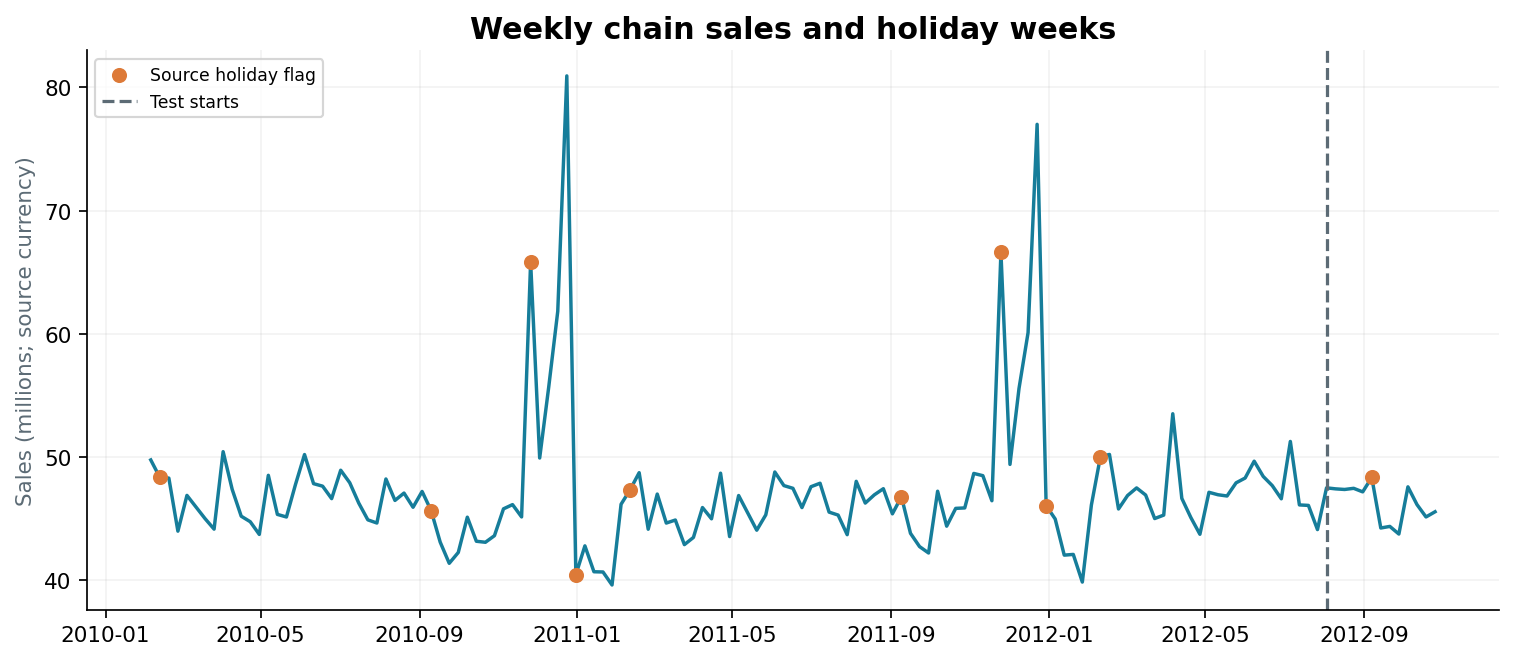

**Why this chart:** A line chart preserves weekly ordering and makes recurring peaks visible.

**Observed insight:** Peak chain week was 2010-12-24, with sales 80,931,416; the test period is marked separately.

**Business implication and risk:** Plan holiday replenishment separately. Deleting legitimate peaks can cause under-ordering.

In [9]:
note = chart_notes[0]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 2

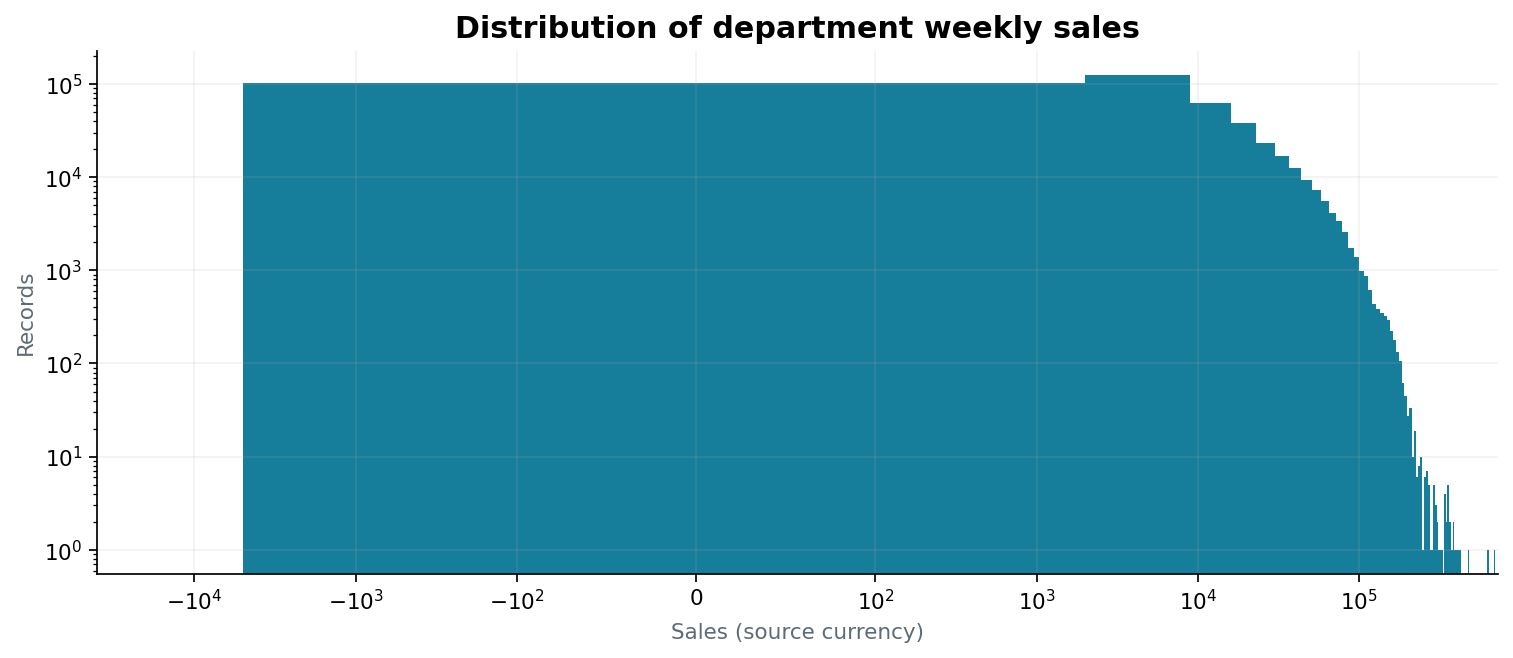

**Why this chart:** Log record counts and a symmetric-log sales axis reveal both returns and a long right tail.

**Observed insight:** Median department-week sales are 7,612; 1,285 rows are negative.

**Business implication and risk:** Use scale-aware errors and preserve possible returns. Revenue forecasts do not directly give unit orders.

In [10]:
note = chart_notes[1]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 3

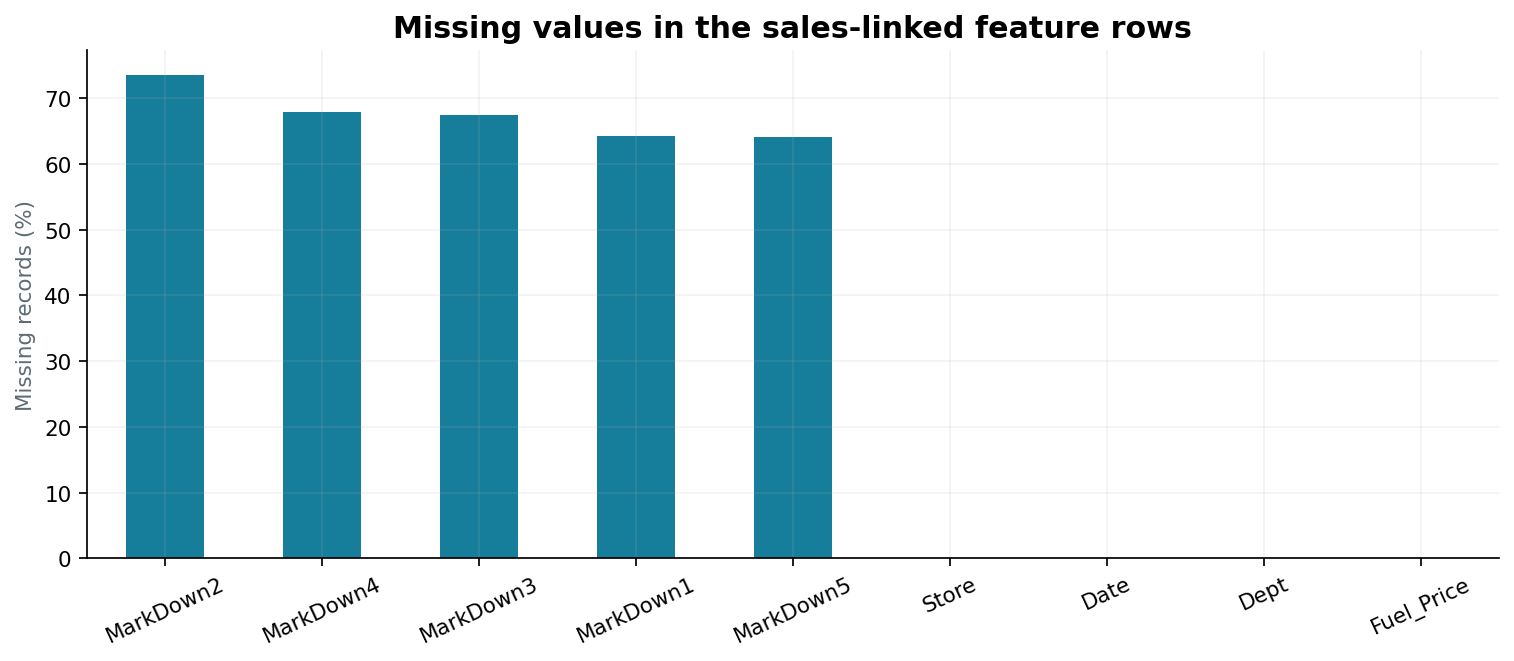

**Why this chart:** A percentage bar chart compares missingness across fields at the modeling grain.

**Observed insight:** MarkDown2 is missing in 73.6% of merged rows. Missing markdowns are not confirmed zero promotions.

**Business implication and risk:** Retain missingness information and monitor promotion-feed coverage; forced zero assumptions can bias decisions.

In [11]:
note = chart_notes[2]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 4

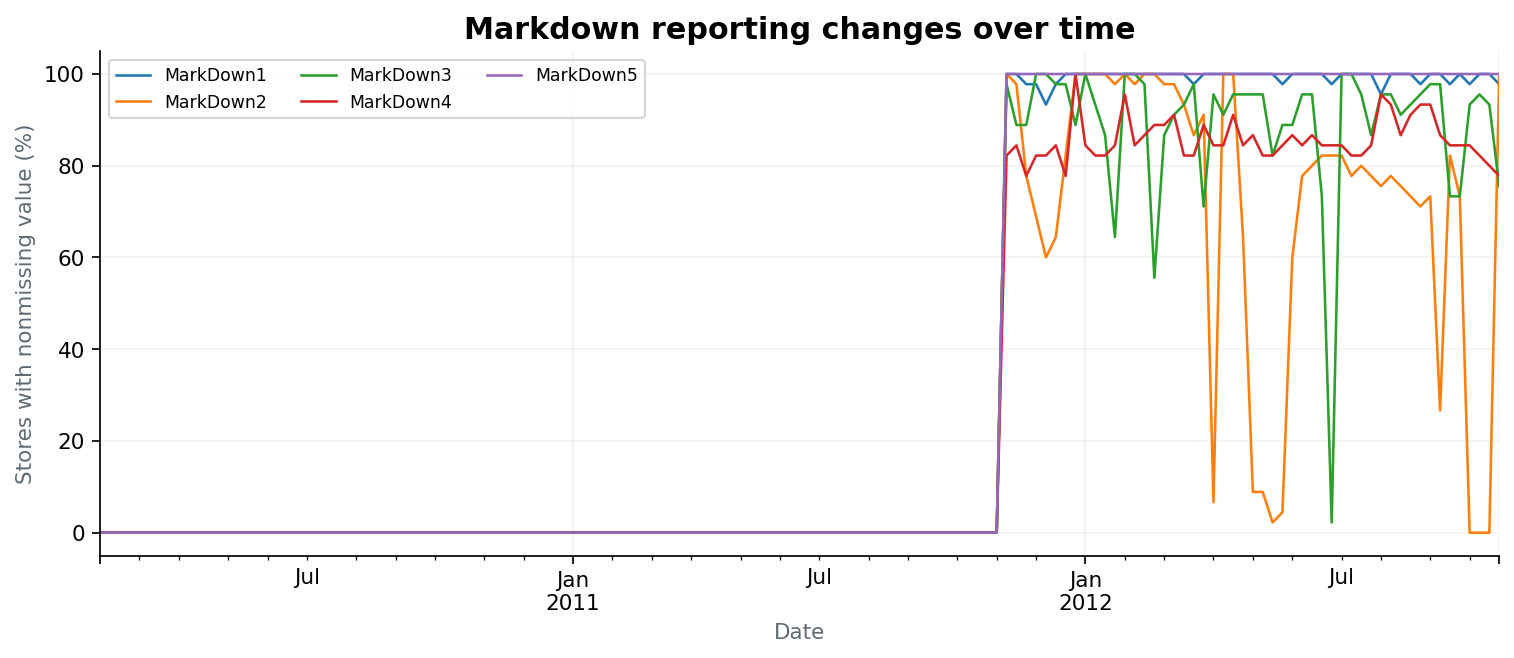

**Why this chart:** Coverage lines distinguish changes in data collection from changes in actual sales.

**Observed insight:** Markdown reporting has a time-dependent availability pattern; earlier missing values cannot be interpreted as measured no-promotion weeks.

**Business implication and risk:** Include availability indicators or native missing handling. Assess promotion effects only where reporting is usable.

In [12]:
note = chart_notes[3]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 5

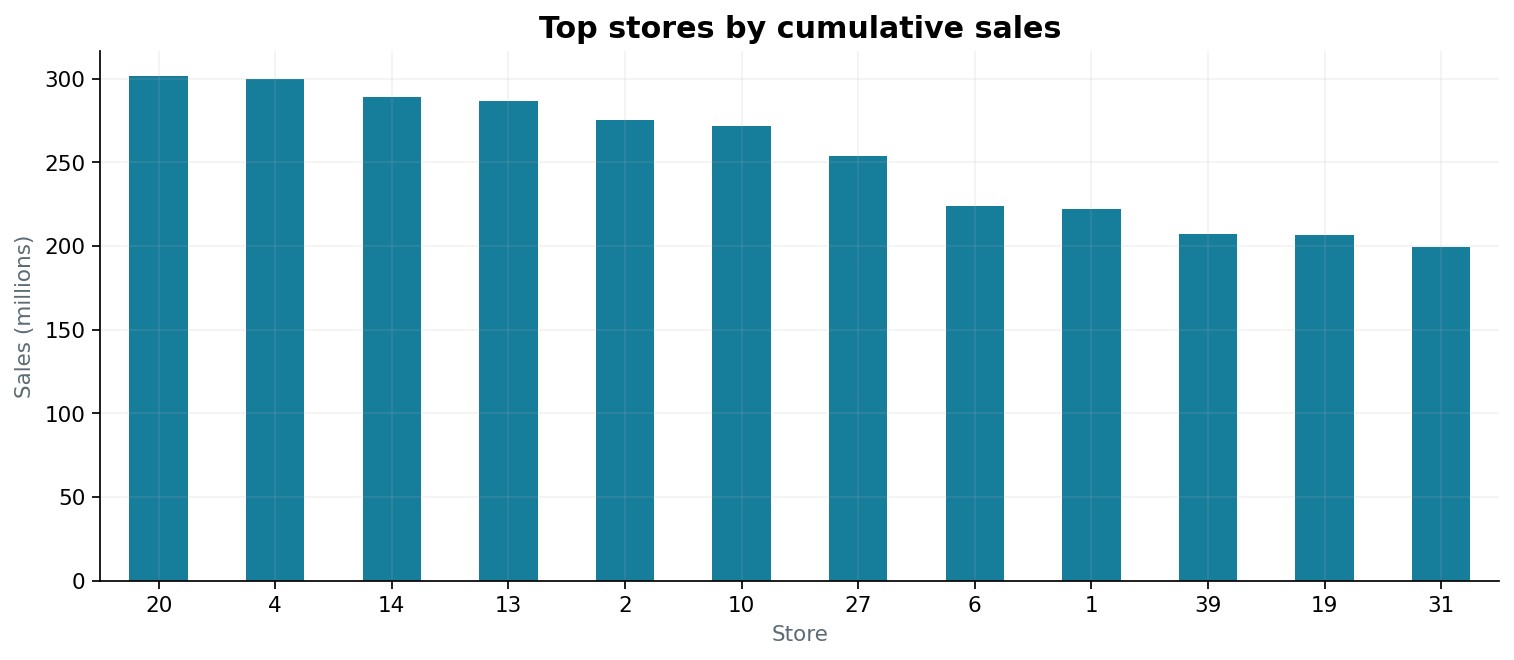

**Why this chart:** Ranked bars compare total commercial scale.

**Observed insight:** Store 20 leads with cumulative sales 301.4 million over the observed period.

**Business implication and risk:** Prioritize availability reviews in large stores, while also tracking efficiency and margin before capital allocation.

In [13]:
note = chart_notes[4]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 6

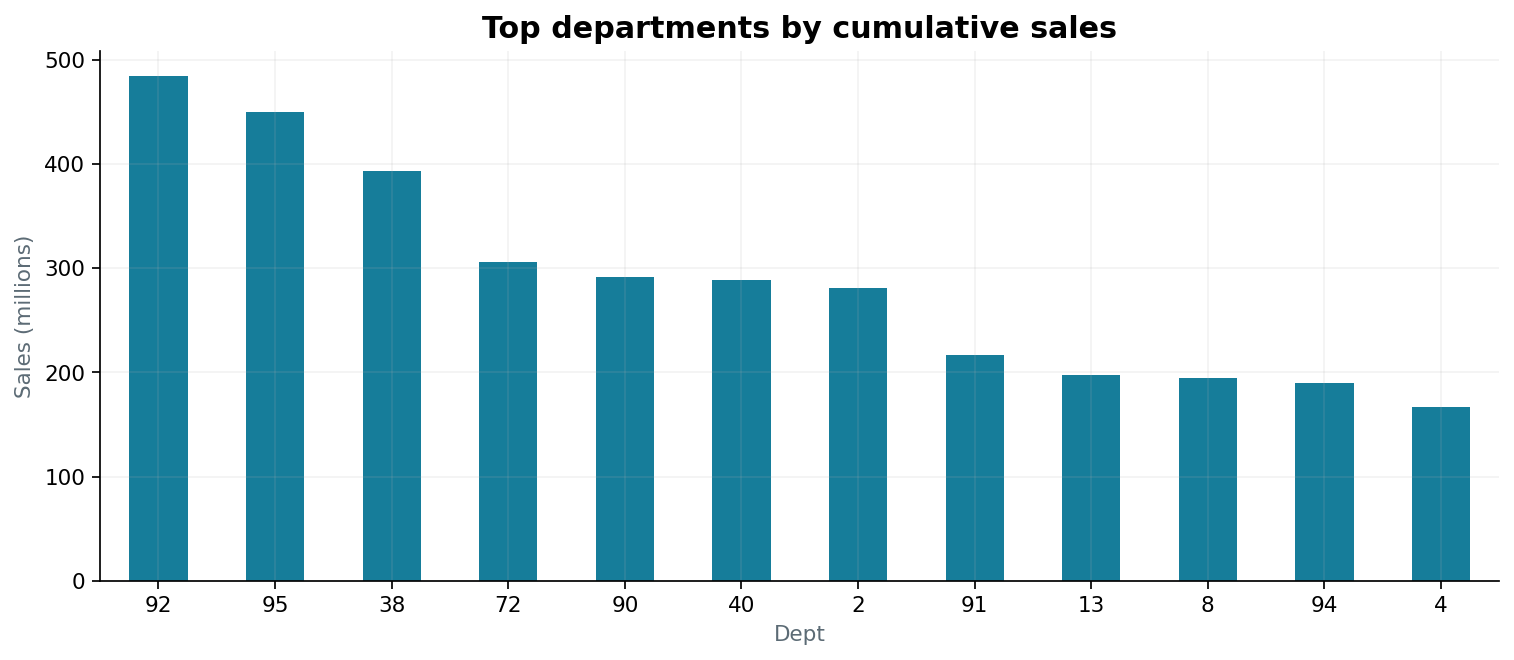

**Why this chart:** Ranked bars show revenue concentration across department IDs.

**Observed insight:** Department 92 has the largest observed cumulative sales. Product names are absent.

**Business implication and risk:** Give high-revenue departments explicit service-level planning; department IDs do not establish product categories.

In [14]:
note = chart_notes[5]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 7

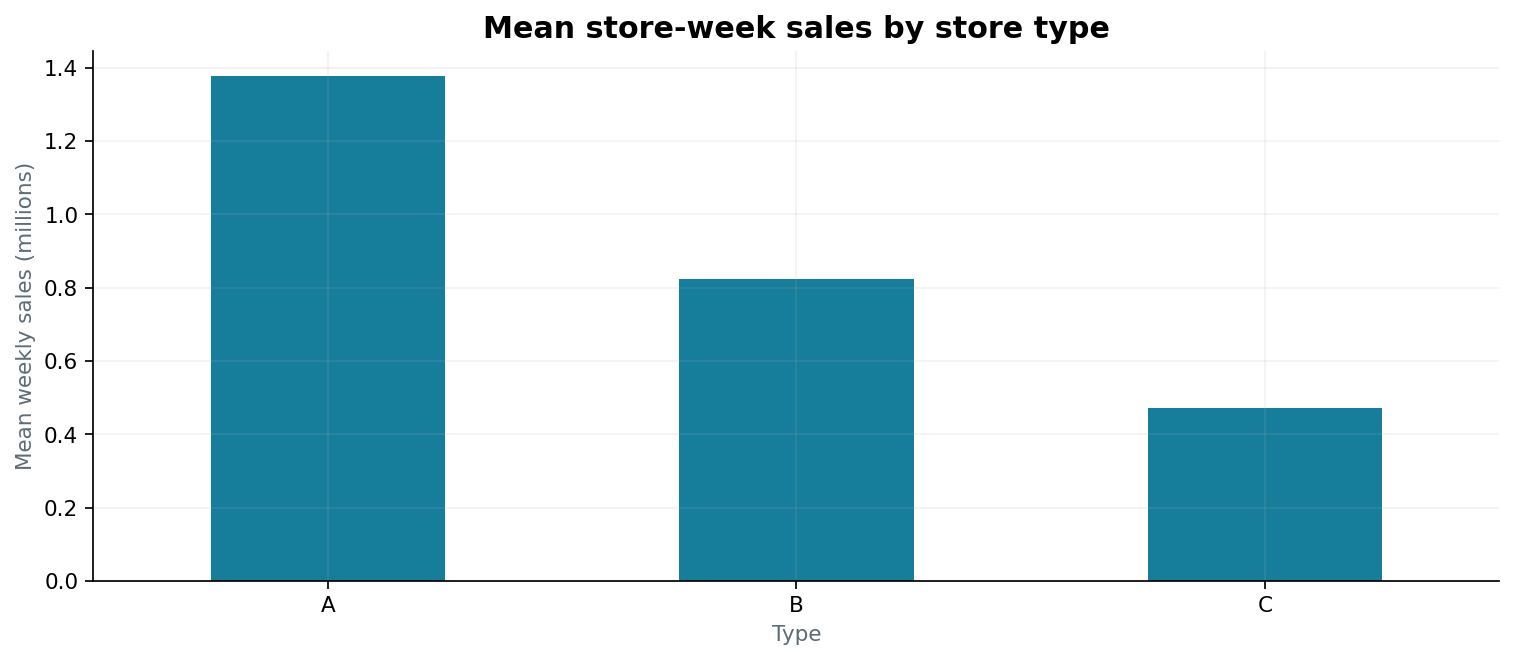

**Why this chart:** Mean store-week aggregation avoids confusing more department rows with larger department demand.

**Observed insight:** Type A has the highest average store-week sales (1.38 million).

**Business implication and risk:** Use type alongside size and local context; the comparison is descriptive and does not show a causal type effect.

In [15]:
note = chart_notes[6]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 8

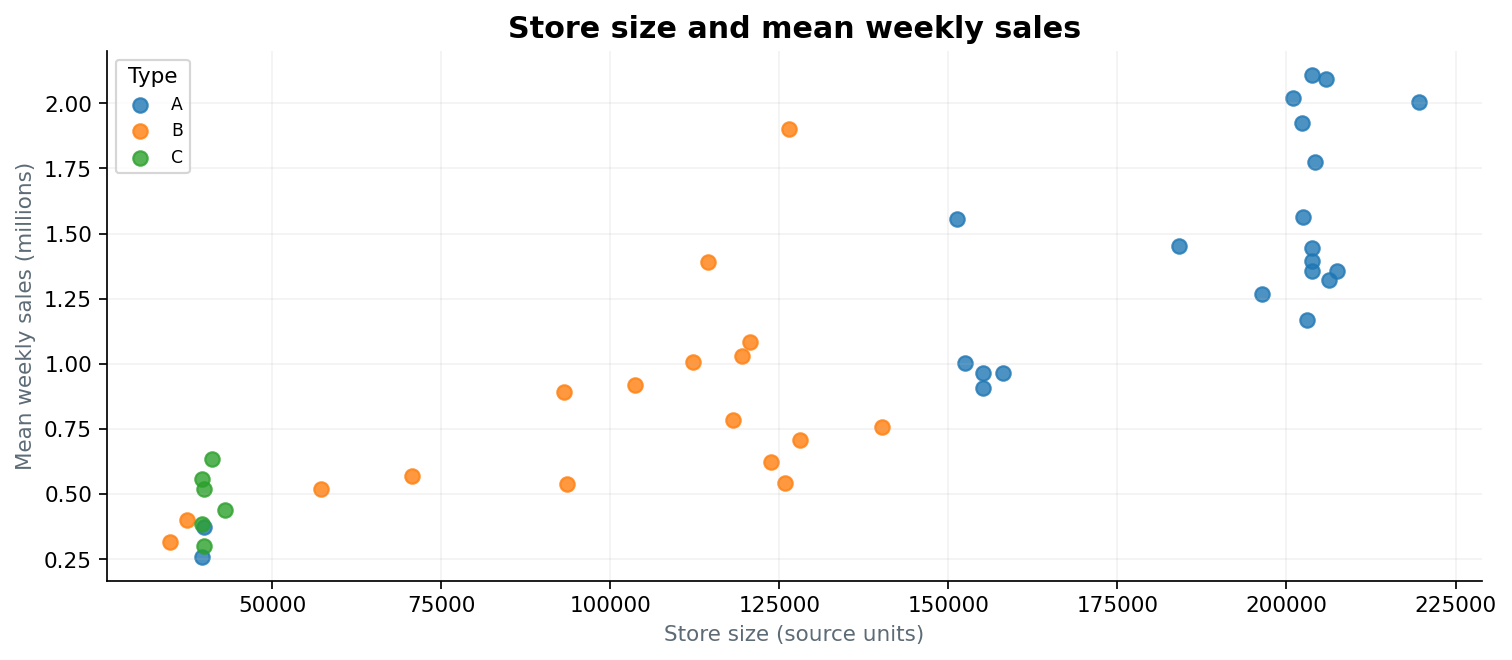

**Why this chart:** A store-level scatterplot reveals scale association without duplicating weekly observations.

**Observed insight:** The store-level Pearson correlation is 0.846; formal rank testing is reported separately.

**Business implication and risk:** Compare sales per size before expansion decisions. Store size alone does not explain local profitability.

In [16]:
note = chart_notes[7]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 9

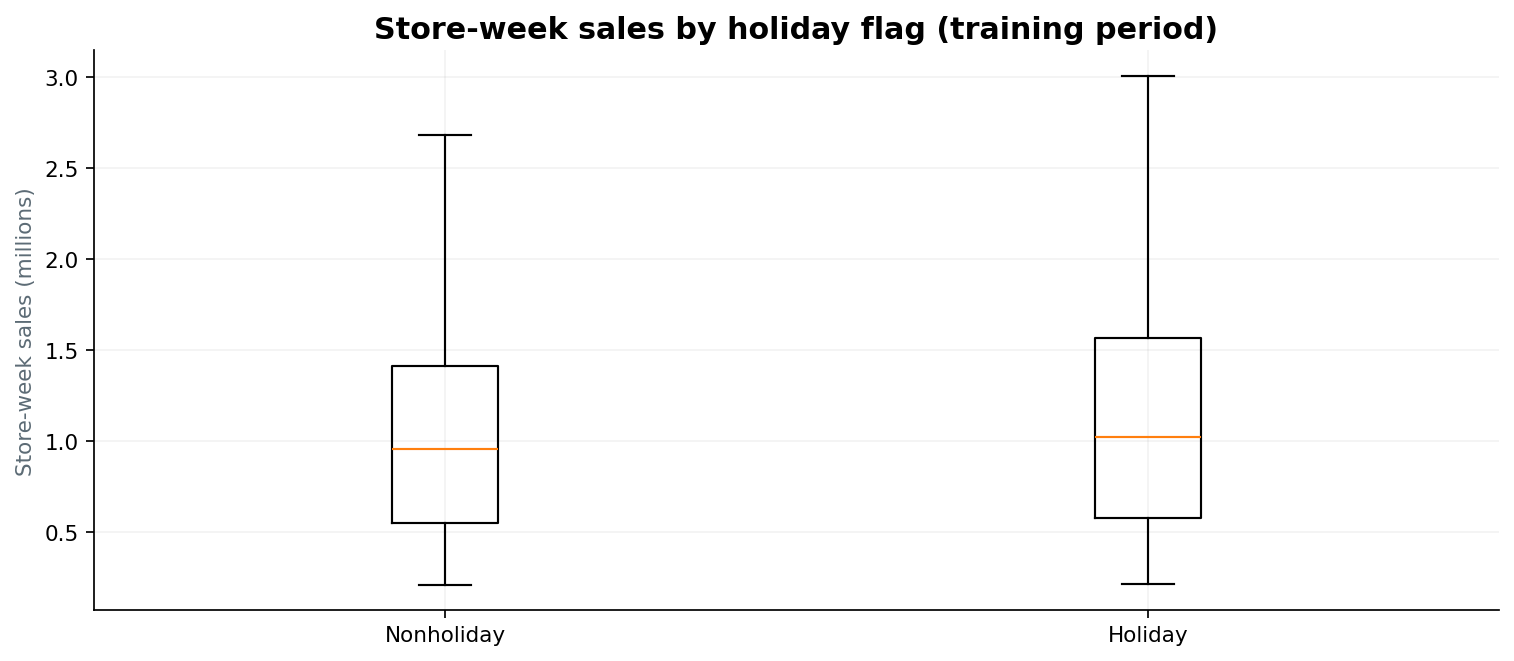

**Why this chart:** Boxplots compare distributions rather than only totals for unequally frequent holiday weeks.

**Observed insight:** Mean holiday store-week sales are 1.13 million versus 1.04 million on nonholidays.

**Business implication and risk:** Plan seasonal peaks, but source flags cover selected holiday weeks and do not capture every festive sales effect.

In [17]:
note = chart_notes[8]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 10

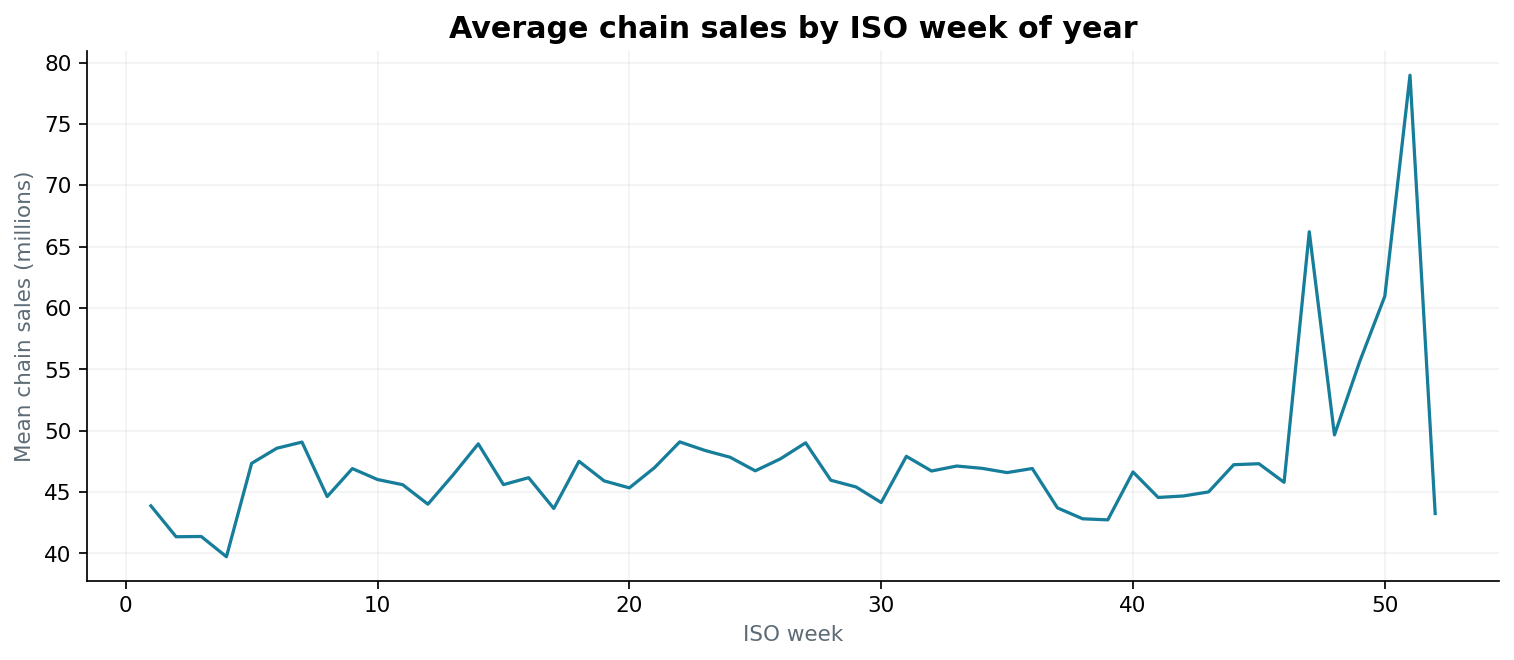

**Why this chart:** A week-of-year profile aligns comparable periods across years.

**Observed insight:** ISO week 51 has the highest average observed chain sales. Only about 2.7 years are available.

**Business implication and risk:** Use seasonal baselines and holiday overrides. Partial years limit confidence in seasonal averages.

In [18]:
note = chart_notes[9]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 11

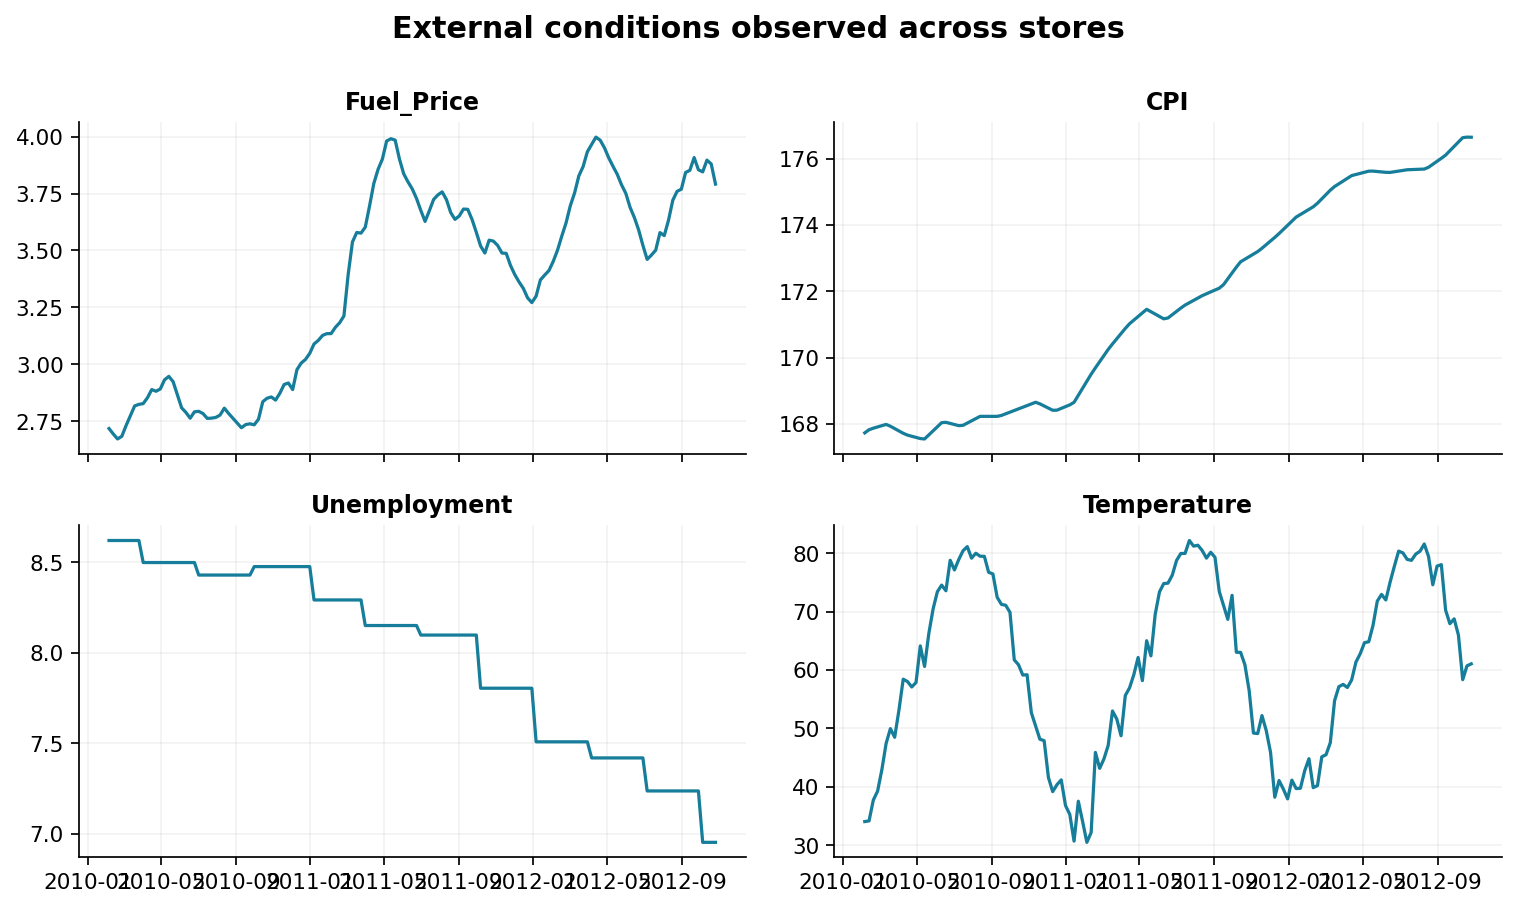

**Why this chart:** Small multiples keep unlike units on separate axes.

**Observed insight:** Fuel, CPI and unemployment evolve over time while temperature exhibits seasonal variation; shared trends can confound sales associations.

**Business implication and risk:** Use prior-week values for forecasting and distinguish association from causal economic impact.

In [19]:
note = chart_notes[10]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 12

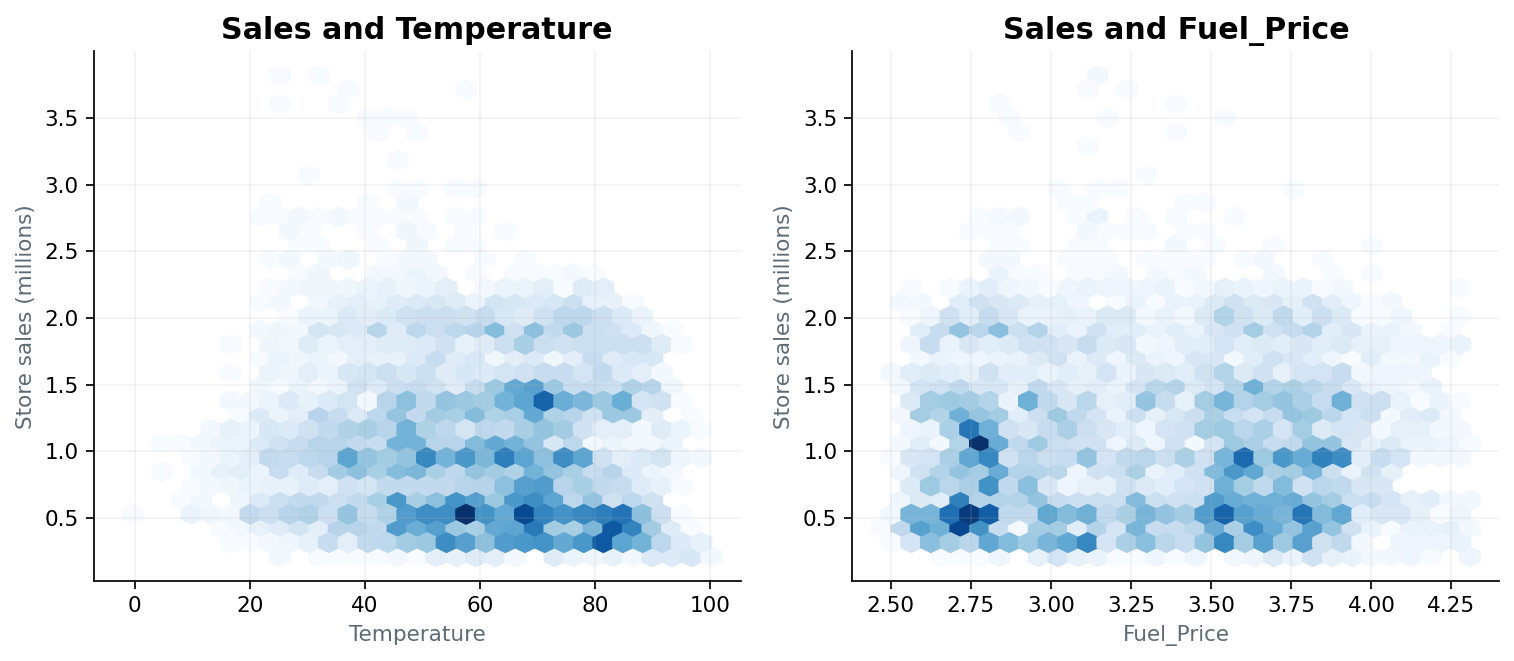

**Why this chart:** Hexagonal density plots avoid severe point overlap.

**Observed insight:** Sales vary widely at similar temperatures and fuel prices, reflecting store mix and other unmeasured factors.

**Business implication and risk:** Do not assign local price or climate causes from this plot; validate incremental forecast value instead.

In [20]:
note = chart_notes[11]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 13

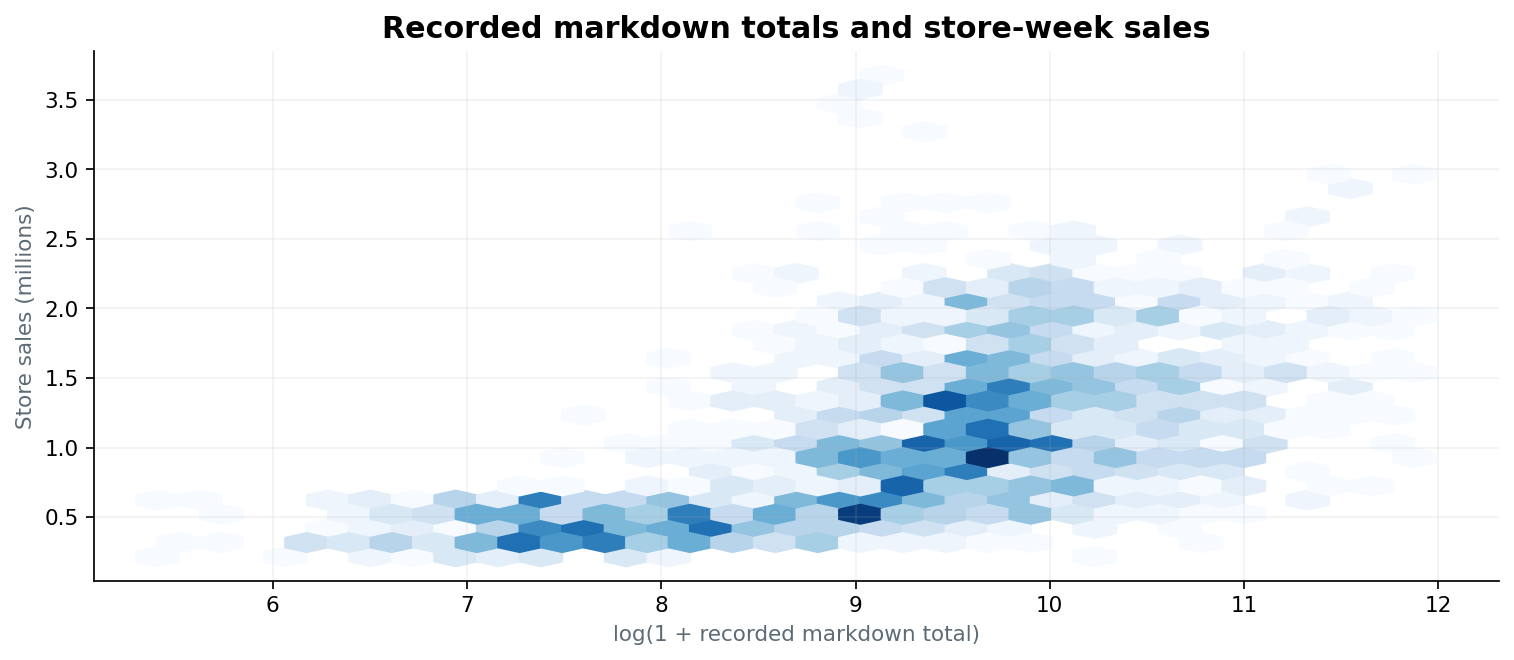

**Why this chart:** A log markdown axis reduces skew and includes only recorded positive promotions.

**Observed insight:** 1,710 training store-weeks have recorded positive markdown totals in this joined view.

**Business implication and risk:** Promotion response requires controls for timing, store scale, prices and margins; correlation alone cannot optimize discounts.

In [21]:
note = chart_notes[12]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 14

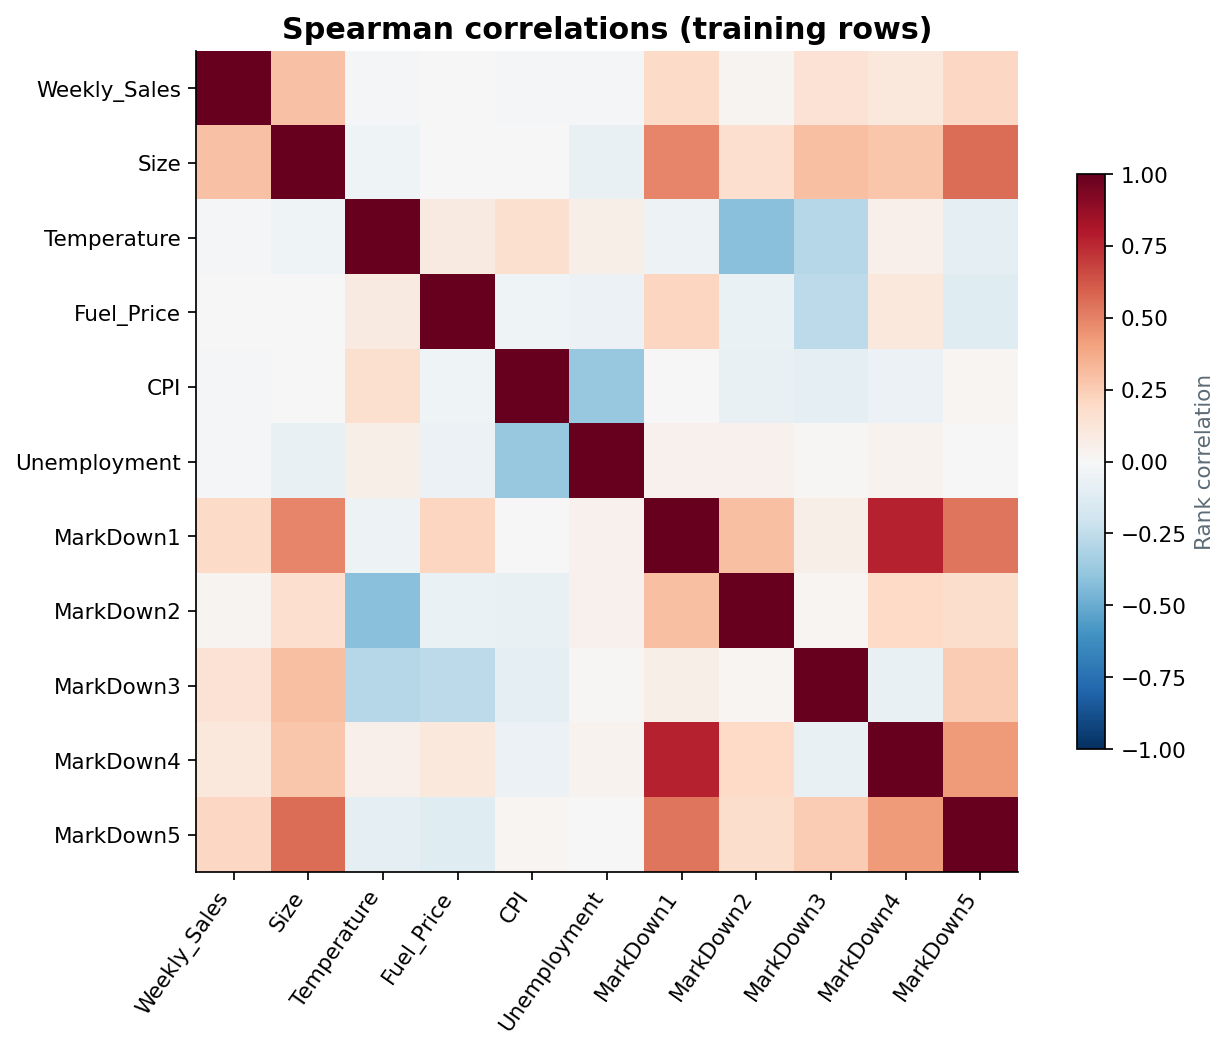

**Why this chart:** Rank correlations are less sensitive to the extreme sales tail and reveal redundant predictors.

**Observed insight:** Several store-level and economic variables are correlated. Each feature is repeated across departments in this modeling-grain summary.

**Business implication and risk:** Use ablation and regularization; these correlations are descriptive and are not independent-observation significance tests.

In [22]:
note = chart_notes[13]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 15

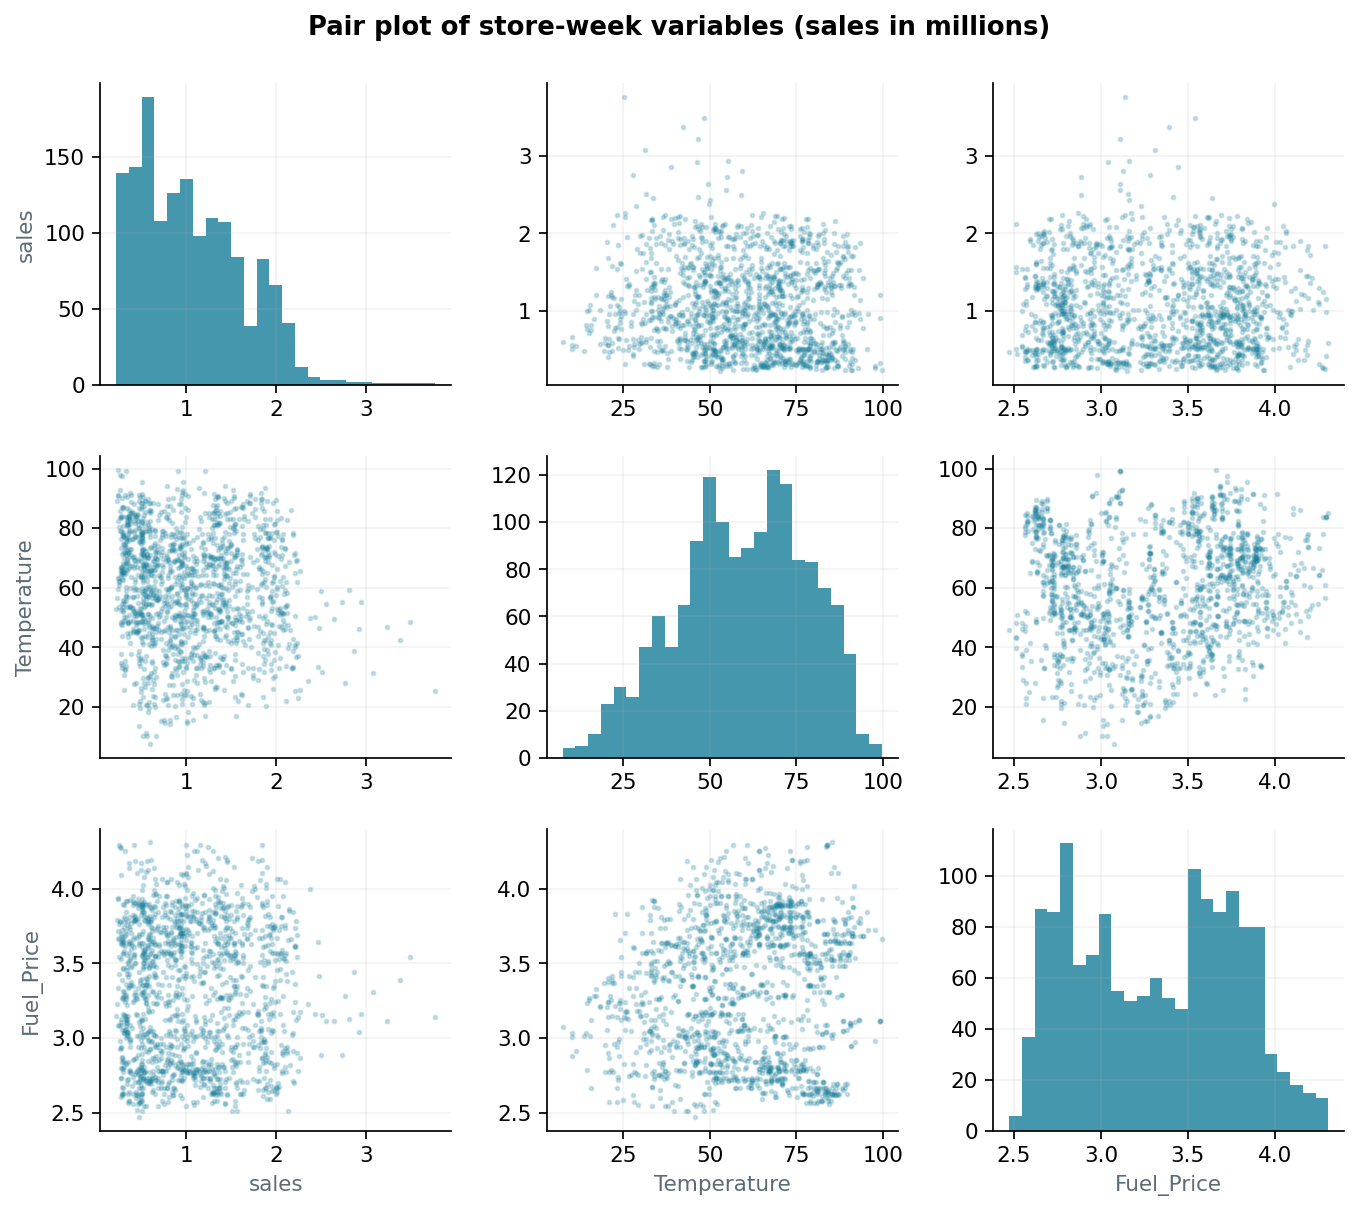

**Why this chart:** A small scatterplot matrix compares marginal distributions and pairwise shapes on a fixed sample.

**Observed insight:** Relationships are dispersed and nonlinear in places; marginal patterns alone do not establish useful predictions.

**Business implication and risk:** Compare nonlinear forecasts against simple baselines with chronological evaluation.

In [23]:
note = chart_notes[14]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 16

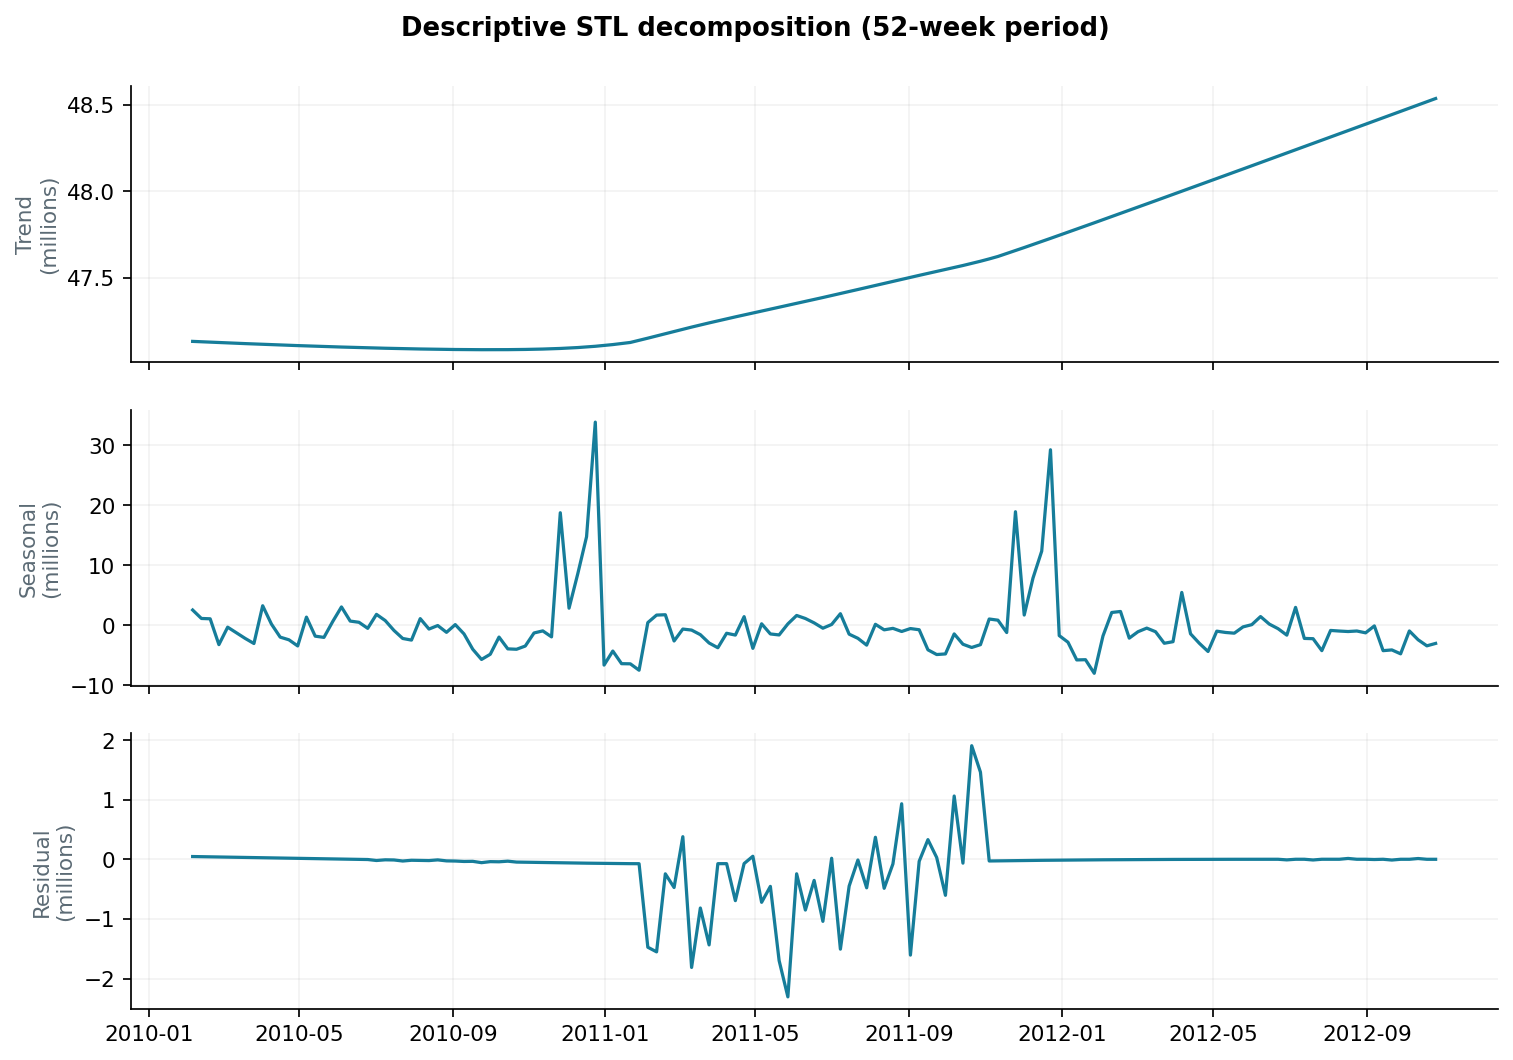

**Why this chart:** STL separates smooth movement, recurring seasonality and residual deviations.

**Observed insight:** Chain sales contain strong recurring variation. This full-history smoother is descriptive and is excluded from forecasting features.

**Business implication and risk:** Schedule staffing and replenishment around seasonality; do not use this two-sided smoother as a real-time predictor.

In [24]:
note = chart_notes[15]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

## 5. Hypothesis Testing
Three exploratory null hypotheses are evaluated: no adjusted holiday association with chain sales; no store-size rank association with average store sales; and no adjusted temperature association with chain sales. The weekly regressions use trend and annual harmonics, with HAC standard errors over four weekly lags. Store size is tested at the store grain with Spearman correlation. Holm correction controls the family of three tests. These observational tests do not establish causal effects, and short history and shared shocks limit inference.

In [25]:
def hypothesis_tests(d, test_start, output):
    """Exploratory tests with week-level HAC uncertainty or store-level sampling."""
    import statsmodels.api as sm
    from statsmodels.stats.multitest import multipletests
    t=d.loc[d.Date.lt(test_start)]
    week=t.groupby('Date').agg(sales=('Weekly_Sales','sum'),holiday=('IsHoliday','first'),temperature=('Temperature','mean'))
    seq=np.arange(len(week)); seasonal=2*np.pi*seq/52.1775
    x=pd.DataFrame({'trend':seq,'sin':np.sin(seasonal),'cos':np.cos(seasonal),
        'sin2':np.sin(2*seasonal),'cos2':np.cos(2*seasonal),'holiday':week.holiday.astype(float).to_numpy()},index=week.index)
    holiday=sm.OLS(week.sales/1e6,sm.add_constant(x)).fit(cov_type='HAC',cov_kwds={'maxlags':4})
    x['temperature']=week.temperature.to_numpy()
    climate=sm.OLS(week.sales/1e6,sm.add_constant(x)).fit(cov_type='HAC',cov_kwds={'maxlags':4})
    perstore=t.groupby(['Store','Date']).Weekly_Sales.sum().groupby('Store').mean()
    size=t.drop_duplicates('Store').set_index('Store').Size.reindex(perstore.index)
    rho,p=stats.spearmanr(size,perstore)
    rows=[{'hypothesis':'Holiday coefficient is zero after trend and annual harmonics','method':'OLS; HAC 4-week standard errors',
        'effect':holiday.params['holiday'],'effect_units':'million sales per chain-week','p_value':holiday.pvalues['holiday'],'n':len(week)},
        {'hypothesis':'Store size and mean weekly store sales have zero rank association','method':'Spearman across stores',
        'effect':rho,'effect_units':'Spearman rho','p_value':p,'n':len(perstore)},
        {'hypothesis':'Temperature coefficient is zero after seasonal and holiday controls','method':'OLS; HAC 4-week standard errors',
        'effect':climate.params['temperature'],'effect_units':'million sales per recorded temperature unit','p_value':climate.pvalues['temperature'],'n':len(week)}]
    result=pd.DataFrame(rows); result['p_Holm']=multipletests(result.p_value,method='holm')[1]; result['reject_5pct']=result.p_Holm.lt(.05)
    result.to_csv(output/'tables/hypothesis_tests.csv',index=False)
    return result

In [26]:
hypotheses = hypothesis_tests(raw, test_start, OUTPUT_DIR)
display(hypotheses)

,hypothesis,method,effect,effect_units,p_value,n,p_Holm,reject_5pct
0,Holiday coefficient is zero after trend and an...,OLS; HAC 4-week standard errors,2.674626,million sales per chain-week,3.767751e-01,130,3.767751e-01,False
1,Store size and mean weekly store sales have ze...,Spearman across stores,0.847353,Spearman rho,2.143091e-13,45,6.429274e-13,True
2,Temperature coefficient is zero after seasonal...,OLS; HAC 4-week standard errors,0.333914,million sales per recorded temperature unit,1.018252e-01,130,2.036504e-01,False


## 6. Feature Engineering and Data Preprocessing
### Missing values, outliers and categorical encoding
No blanket row deletion is used. Ridge learns median imputation and missingness indicators from its training fold and one-hot encodes store, department and type. Boosting treats these three fields as categorical and uses native missing branches. True or suspected returns and seasonal peaks remain observed outcomes. The anomaly section creates review proposals without replacing reported model targets.

### Feature manipulation, transformation and selection
Exact-date lag lookups avoid crossing gaps. Trailing means exclude the target week. Calendar features are known in advance; external predictors use the prior calendar week. Store size is numeric. Ridge scales numeric features after imputation. Alternative feature sets compare the core sales/calendar model with lagged external variables. PCA is reserved for visualizing store segments; forecast dimensionality reduction is not required.

### Text preprocessing and class balance
Not applicable: there is no free text target or supervised classification label. No SMOTE or class resampling is used. Holiday weighting is an error metric, not synthetic balancing.

### Chronological splitting
Three expanding 8-week validation windows precede the final 13-week test. Imputation and fitted transformations live inside models. For later weeks in a one-step evaluation, previous actual sales are allowed. Fixed-origin multiweek scoring uses generated lags instead.

In [27]:
def engineer(data):
    """Use exact calendar lookups. No centered windows or target-week covariates."""
    d = data.copy()
    d['TypeCode'] = d.Type.map({'A': 0, 'B': 1, 'C': 2}).astype(float)
    week = d.Date.dt.isocalendar().week.astype(int)
    d['week_sin'] = np.sin(2 * np.pi * week / 52.1775)
    d['week_cos'] = np.cos(2 * np.pi * week / 52.1775)
    d['month'] = d.Date.dt.month
    # Absolute date origin is fixed and does not depend on future data.
    d['trend'] = (d.Date - pd.Timestamp('2010-01-01')).dt.days / 7
    lookup = d.set_index(KEY + ['Date']).Weekly_Sales
    lag_values = {}
    for lag in sorted(set([1, 4, 13, 52] + list(range(1, 14)))):
        idx = pd.MultiIndex.from_arrays([d.Store, d.Dept, d.Date - pd.Timedelta(weeks=lag)])
        lag_values[lag] = lookup.reindex(idx).to_numpy()
    for lag in [1, 4, 13, 52]:
        d[f'lag{lag}'] = lag_values[lag]
    for window in [4, 13]:
        d[f'rolling{window}'] = pd.DataFrame({i: lag_values[i] for i in range(1, window + 1)}).mean(axis=1).to_numpy()
    d['history_count'] = pd.DataFrame(lag_values).notna().sum(axis=1).to_numpy()
    storeweek = d.drop_duplicates(['Store', 'Date']).set_index(['Store', 'Date'])
    idx = pd.MultiIndex.from_arrays([d.Store, d.Date - pd.Timedelta(weeks=1)])
    for col in EXTERNAL:
        d[f'{col}_lag1'] = storeweek[col].reindex(idx).to_numpy()
    return d

def metrics(y, pred, holidays):
    y, pred = np.asarray(y), np.asarray(pred)
    err = y - pred
    return {'MAE': float(np.abs(err).mean()), 'RMSE': float(np.sqrt(np.mean(err ** 2))),
        'WAPE': float(np.abs(err).sum() / max(np.abs(y).sum(), 1)),
        'weighted_MAE': float(np.average(np.abs(err), weights=np.where(holidays, 5, 1))),
        'bias': float(np.mean(pred - y)), 'n': len(y)}

def baseline(train, target, mode='seasonal'):
    """Fallback statistics fitted on the origin's history only."""
    means = train.groupby(KEY).Weekly_Sales.mean()
    fallback = pd.MultiIndex.from_frame(target[KEY]).map(means).to_numpy(dtype=float)
    fallback = np.nan_to_num(fallback, nan=train.Weekly_Sales.median())
    source = target['lag1' if mode == 'last' else 'lag52'].to_numpy()
    return np.where(np.isfinite(source), source, fallback)

def build_model(name, columns, params=None):
    params = params or {}
    if name == 'baseline':
        return CalendarBaseline(mode=params.get('mode', 'seasonal'))
    if name == 'ridge':
        numeric = [c for c in columns if c not in CAT]
        pre = ColumnTransformer([
            ('numeric', make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()), numeric),
            ('category', OneHotEncoder(handle_unknown='ignore'), CAT)])
        return make_pipeline(pre, Ridge(alpha=params.get('alpha', 100), solver='lsqr'))
    if name == 'boosting':
        return HistGradientBoostingRegressor(loss='squared_error', max_iter=100,
            max_leaf_nodes=params.get('max_leaf_nodes', 31), learning_rate=.09,
            l2_regularization=10, min_samples_leaf=30, categorical_features=CAT,
            early_stopping=False, random_state=SEED)
    raise ValueError(name)

In [28]:
d = engineer(raw)
display(d[['Store','Dept','Date','Weekly_Sales','lag1','lag52','rolling4','CPI_lag1']].tail())
print('Core features:', CORE)
print('Additional lagged external features:', EXT)


,Store,Dept,Date,Weekly_Sales,lag1,lag52,rolling4,CPI_lag1
421565,45,98,2012-09-28,508.37,467.30,727.05,442.9350,191.856704
421566,45,98,2012-10-05,628.10,508.37,894.98,483.5175,192.013558
421567,45,98,2012-10-12,1061.02,628.10,996.40,552.4325,192.170412
421568,45,98,2012-10-19,760.01,1061.02,1058.84,666.1975,192.327265
421569,45,98,2012-10-26,1076.80,760.01,1167.90,739.3750,192.330854


Core features: ['Store', 'Dept', 'TypeCode', 'Size', 'IsHoliday', 'week_sin', 'week_cos', 'month', 'trend', 'lag1', 'lag4', 'lag13', 'lag52', 'rolling4', 'rolling13', 'history_count']
Additional lagged external features: ['Temperature_lag1', 'Fuel_Price_lag1', 'CPI_lag1', 'Unemployment_lag1', 'MarkDown1_lag1', 'MarkDown2_lag1', 'MarkDown3_lag1', 'MarkDown4_lag1', 'MarkDown5_lag1']


## 7. ML Model Implementation
### Model 1: interpretable baselines and ridge regression
Last-week and annual seasonal baselines establish whether machine learning adds value. Ridge uses alpha values 10 and 1000 with training-fold preprocessing.

### Model 2: histogram gradient boosting
Nonlinear interactions among lagged demand, calendar and store/dept attributes are learned with 15 or 31 leaves, 100 iterations and fixed learning rate 0.09. Random early-stopping splits are disabled.

### Model 3: external-feature boosting and ablation
A matched 31-leaf model adds lagged temperature, fuel, CPI, unemployment and markdown measures. This tests incremental predictive value without reading target-week observed inputs.

### Cross-validation, tuning and metrics
Candidate choice uses mean MAE across validation windows. Test results are reported after selection. MAE measures typical absolute revenue error; RMSE emphasizes costly large misses; WAPE gives a scale-relative chain summary; holiday-weighted MAE gives holiday rows five times the weight. Bias shows systematic over/underprediction.

In [29]:
def fit_forecasts(d, output):
    """Three expanding-window folds select the model before touching final 13 weeks."""
    dates = np.sort(d.Date.unique())
    test_start = pd.Timestamp(dates[-13])
    pretest = d.Date.lt(test_start)
    candidates = [
        ('last_week', 'baseline', CORE, {'mode':'last'}), ('seasonal_52', 'baseline', CORE, {'mode':'seasonal'}),
        ('ridge_10', 'ridge', CORE, {'alpha': 10}),
        ('ridge_1000', 'ridge', CORE, {'alpha': 1000}),
        ('boost_15', 'boosting', CORE, {'max_leaf_nodes': 15}),
        ('boost_31', 'boosting', CORE, {'max_leaf_nodes': 31}),
        ('boost_external', 'boosting', CORE + EXT, {'max_leaf_nodes': 31})]
    rows = []
    for fold, offset in enumerate([37, 29, 21], 1):
        start, end = pd.Timestamp(dates[-offset]), pd.Timestamp(dates[-offset + 8])
        train = d.loc[d.Date.lt(start)]
        val = d.loc[d.Date.ge(start) & d.Date.lt(end)]
        LOG.info('Forecast CV fold %s: %s to %s', fold, start.date(), end.date())
        for label, kind, columns, params in candidates:
            if kind:
                model = build_model(kind, columns, params)
                model.fit(train[columns], train.Weekly_Sales)
                pred = model.predict(val[columns])
            else:
                pred = baseline(train, val, 'last' if label == 'last_week' else 'seasonal')
            rows.append({'model': label, 'fold': fold, 'train_end': str(train.Date.max().date()),
                'valid_start': str(start.date()), 'valid_end': str(val.Date.max().date()),
                **metrics(val.Weekly_Sales, pred, val.IsHoliday)})
    cv = pd.DataFrame(rows)
    cv.to_csv(output / 'tables/cross_validation.csv', index=False)
    ranking = cv.groupby('model').MAE.mean().sort_values()
    winner = ranking.index[0]
    LOG.info('Chosen on CV only: %s', winner)
    train, test = d.loc[pretest], d.loc[~pretest]
    models, results = {}, []
    predictions = test[KEY + ['Date', 'IsHoliday', 'Weekly_Sales']].copy()
    for label, kind, columns, params in candidates:
        if kind:
            model = build_model(kind, columns, params)
            model.fit(train[columns], train.Weekly_Sales)
            pred = model.predict(test[columns])
            models[label] = {'model': model, 'columns': columns, 'kind': kind, 'params': params}
            joblib.dump({**models[label], 'label':label, 'train_end':str(train.Date.max().date())},
                output / f'models/evaluated_{label}.joblib')
        else:
            pred = baseline(train, test, 'last' if label == 'last_week' else 'seasonal')
        predictions[label] = pred
        results.append({'model': label, 'CV_MAE': ranking[label], **metrics(test.Weekly_Sales, pred, test.IsHoliday)})
    scores = pd.DataFrame(results).sort_values('CV_MAE')
    scores.to_csv(output / 'tables/forecast_metrics.csv', index=False)
    predictions['selected_prediction'] = predictions[winner]
    predictions.to_csv(output / 'tables/holdout_predictions.csv', index=False)
    by_series = []
    for (store, dept), part in predictions.groupby(KEY):
        by_series.append({'Store':store, 'Dept':dept,
            **metrics(part.Weekly_Sales, part.selected_prediction, part.IsHoliday)})
    pd.DataFrame(by_series).to_csv(output / 'tables/forecast_errors_by_series.csv', index=False)
    # Permutation importance uses validation dates and an earlier training fit, not test.
    if winner in models:
        spec = models[winner]
        val_start = pd.Timestamp(dates[-21])
        val_end = pd.Timestamp(dates[-13])
        explainer = build_model(spec['kind'], spec['columns'], spec['params'])
        explainer.fit(d.loc[d.Date.lt(val_start), spec['columns']], d.loc[d.Date.lt(val_start), 'Weekly_Sales'])
        val = d.loc[d.Date.ge(val_start) & d.Date.lt(val_end)].sample(n=min(5000, int((d.Date.ge(val_start) & d.Date.lt(val_end)).sum())), random_state=SEED)
        imp = permutation_importance(explainer, val[spec['columns']], val.Weekly_Sales,
            scoring='neg_mean_absolute_error', n_repeats=3, random_state=SEED, n_jobs=1)
        importance = pd.DataFrame({'feature': spec['columns'], 'MAE_increase': imp.importances_mean,
            'std': imp.importances_std}).sort_values('MAE_increase', ascending=False)
    else:
        importance = pd.DataFrame({'feature': ['lag1' if winner == 'last_week' else 'lag52'], 'MAE_increase': [np.nan], 'std': [np.nan]})
    importance.to_csv(output / 'tables/feature_importance.csv', index=False)
    selected = models.get(winner)
    if selected:
        joblib.dump({**selected, 'label': winner, 'train_end': str(train.Date.max().date())}, output / 'models/holdout_forecaster.joblib')
        loaded = joblib.load(output / 'models/holdout_forecaster.joblib')
        np.testing.assert_allclose(loaded['model'].predict(test[loaded['columns']].head(100)), predictions[winner].head(100))
    return {'winner': winner, 'cv': cv, 'scores': scores, 'predictions': predictions,
        'models': models, 'test_start': test_start, 'importance': importance}

In [30]:
forecast_result = fit_forecasts(d, OUTPUT_DIR)
display(forecast_result['cv'])
display(forecast_result['scores'])
print('Selected using CV only:', forecast_result['winner'])
display(forecast_result['importance'])
state['data'] = d
state['forecast'] = forecast_result


,model,fold,train_end,valid_start,valid_end,MAE,RMSE,WAPE,weighted_MAE,bias,n
0,last_week,1,2012-02-10,2012-02-17,2012-04-06,1851.079008,4363.153910,0.115639,1851.079008,-145.186849,23801
1,seasonal_52,1,2012-02-10,2012-02-17,2012-04-06,1897.626786,4144.486522,0.118547,1897.626786,-808.131396,23801
2,ridge_10,1,2012-02-10,2012-02-17,2012-04-06,2868.281010,4477.736220,0.179185,2868.281010,-1585.526700,23801
3,ridge_1000,1,2012-02-10,2012-02-17,2012-04-06,2892.631649,4497.747488,0.180707,2892.631649,-1683.358697,23801
4,boost_15,1,2012-02-10,2012-02-17,2012-04-06,1685.104561,3771.732767,0.105271,1685.104561,-16.137495,23801
5,boost_31,1,2012-02-10,2012-02-17,2012-04-06,1611.630375,3604.710896,0.100681,1611.630375,89.427851,23801
6,boost_external,1,2012-02-10,2012-02-17,2012-04-06,1589.501068,3558.345000,0.099298,1589.501068,55.257883,23801
7,last_week,2,2012-04-06,2012-04-13,2012-06-01,1735.983074,3875.911876,0.110322,1735.983074,228.533920,23671
8,seasonal_52,2,2012-04-06,2012-04-13,2012-06-01,1982.906812,4401.847408,0.126015,1982.906812,-194.270068,23671
9,ridge_10,2,2012-04-06,2012-04-13,2012-06-01,2085.591118,3607.613552,0.132540,2085.591118,-138.957642,23671


,model,CV_MAE,MAE,RMSE,WAPE,weighted_MAE,bias,n
0,last_week,1740.700898,1516.365391,3434.501194,0.097073,1661.739364,-26.269990,38530
6,boost_external,1812.356009,1235.861846,2633.079577,0.079116,1319.861114,-212.626601,38530
5,boost_31,1826.723557,1231.777411,2592.712670,0.078854,1315.272862,-200.958809,38530
4,boost_15,1827.697195,1321.967040,2770.053027,0.084628,1410.589290,-210.190402,38530
1,seasonal_52,1871.439935,1689.999806,3625.772145,0.108188,1714.505857,-215.923309,38530
3,ridge_1000,2304.385001,1921.301204,3267.631063,0.122996,1988.342554,-440.306304,38530
2,ridge_10,2320.162005,1967.827156,3294.512966,0.125974,2030.992675,-381.269215,38530


Selected using CV only: last_week


,feature,MAE_increase,std
9,lag1,18427.910356,125.086825
1,Dept,222.302225,22.585022
0,Store,58.427667,3.236464
2,TypeCode,0.000000,0.000000
4,IsHoliday,0.000000,0.000000
5,week_sin,0.000000,0.000000
6,week_cos,0.000000,0.000000
3,Size,0.000000,0.000000
7,month,0.000000,0.000000
8,trend,0.000000,0.000000


### Short and long horizons
The 1/4/13-week fixed-origin test prevents later actual sales from entering lag features. Unknown external values persist from the origin. The annual backtest evaluates a transparent seasonal baseline. Forecast files cover active store-department pairs; the annual planning product is distinct from the short learned forecast. These forecasts start after the historical sales end date, not today.

In [31]:
def recursive_forecast(history, dates, stores, features, spec=None):
    """Fixed-origin forecasts: generated sales feed future lags; external inputs persist.

    Feature file future holiday dates are calendar information only. Future observed
    prices, markdowns and economic indicators are never read by this function.
    """
    last = history.groupby(KEY).tail(1)
    # Forecast only series active in the last 13 weeks; discontinued pairs are excluded.
    pairs = history.loc[history.Date.gt(history.Date.max() - pd.Timedelta(weeks=13)), KEY].drop_duplicates()
    pair_index = pd.MultiIndex.from_frame(pairs)
    sales = history.pivot(index='Date', columns=KEY, values='Weekly_Sales').reindex(columns=pair_index)
    fallback = history.groupby(KEY).Weekly_Sales.mean().reindex(pair_index).to_numpy()
    last_external = history.sort_values('Date').drop_duplicates('Store', keep='last').set_index('Store')[EXTERNAL]
    holiday = features.groupby('Date').IsHoliday.first().to_dict()
    # Source flags identify holiday weeks; projected year uses the same week 52 weeks ago.
    old_holiday = history.groupby('Date').IsHoliday.first().to_dict()
    attrs = pairs.merge(stores, on='Store', validate='many_to_one')
    rows = []
    for date in pd.to_datetime(dates):
        x = attrs.copy()
        x['Date'] = date
        x['IsHoliday'] = holiday.get(date, old_holiday.get(date - pd.Timedelta(weeks=52), False))
        x['TypeCode'] = x.Type.map({'A': 0, 'B': 1, 'C': 2})
        week = date.isocalendar().week
        x['week_sin'], x['week_cos'] = np.sin(2*np.pi*week/52.1775), np.cos(2*np.pi*week/52.1775)
        x['month'], x['trend'] = date.month, (date-pd.Timestamp('2010-01-01')).days/7
        lagged = np.array([sales.loc[date-pd.Timedelta(weeks=i)].to_numpy()
            if date-pd.Timedelta(weeks=i) in sales.index else np.full(len(pairs), np.nan) for i in range(1,14)])
        for i in [1,4,13,52]:
            dt = date-pd.Timedelta(weeks=i)
            x[f'lag{i}'] = sales.loc[dt].to_numpy() if dt in sales.index else np.nan
        for win in [4,13]:
            x[f'rolling{win}'] = pd.DataFrame(lagged[:win]).mean(axis=0).to_numpy()
        x['history_count'] = np.isfinite(lagged).sum(axis=0) + x.lag52.notna().astype(int).to_numpy()
        for col in EXTERNAL:
            x[f'{col}_lag1'] = x.Store.map(last_external[col])
        if spec:
            pred = spec['model'].predict(x[spec['columns']])
        else:
            pred = x.lag52.fillna(pd.Series(fallback)).to_numpy()
        if not np.isfinite(pred).all():
            raise ValueError('Non-finite recursive forecasts')
        sales.loc[date] = pred
        x['forecast'] = pred
        rows.append(x[KEY+['Date', 'IsHoliday', 'forecast']])
    return pd.concat(rows, ignore_index=True)

def horizon_analysis(d, feature_file, stores, forecasts, output):
    start = forecasts['test_start']
    hist = d.loc[d.Date.lt(start)]
    dates = sorted(d.loc[d.Date.ge(start), 'Date'].unique())
    spec = forecasts['models'].get(forecasts['winner'])
    # Last-week winner is represented explicitly rather than replaced by seasonal.
    fixed = recursive_forecast(hist, dates, stores, feature_file, spec)
    compare = fixed.merge(d[KEY+['Date','Weekly_Sales']], on=KEY+['Date'], validate='one_to_one')
    rows = []
    for horizon in [1,4,13]:
        subset = compare.loc[compare.Date.isin(dates[:horizon])]
        rows.append({'model': forecasts['winner'], 'horizon_weeks': horizon,
            'protocol': 'fixed origin; recursive lags; persistent external inputs',
            **metrics(subset.Weekly_Sales, subset.forecast, subset.IsHoliday)})
    fixed.to_csv(output / 'tables/fixed_origin_predictions.csv', index=False)
    # A full-year seasonal backtest is possible with about 91 weeks of prior history.
    long_start = pd.Timestamp(sorted(d.Date.unique())[-52])
    long_history = d.loc[d.Date.lt(long_start)]
    long_dates = sorted(d.loc[d.Date.ge(long_start), 'Date'].unique())
    long_pred = recursive_forecast(long_history, long_dates, stores, feature_file)
    check = long_pred.merge(d[KEY+['Date','Weekly_Sales']], on=KEY+['Date'], validate='one_to_one')
    rows.append({'model':'seasonal_52', 'horizon_weeks':52,
        'protocol':'fixed origin; seasonal baseline; active pairs only',
        **metrics(check.Weekly_Sales, check.forecast, check.IsHoliday)})
    check.to_csv(output / 'tables/long_horizon_backtest.csv', index=False)
    horizon_scores = pd.DataFrame(rows)
    horizon_scores.to_csv(output / 'tables/horizon_metrics.csv', index=False)
    # Refit only after all evaluation and explainability calculations are finished.
    if forecasts['winner'] in forecasts['models']:
        spec = forecasts['models'][forecasts['winner']]
        final = build_model(spec['kind'], spec['columns'], spec['params'])
        final.fit(d[spec['columns']], d.Weekly_Sales)
        final_spec = {**spec, 'model':final, 'label':forecasts['winner'], 'train_end':str(d.Date.max().date())}
        joblib.dump(final_spec, output / 'models/forecaster.joblib')
    else:
        final_spec = None
        joblib.dump({'label':forecasts['winner'], 'kind':'baseline'}, output/'models/forecaster.joblib')
    future_dates = pd.date_range(d.Date.max()+pd.Timedelta(weeks=1),periods=52,freq='7D')
    future_short = recursive_forecast(d, future_dates[:13], stores, feature_file, final_spec)
    future_long = recursive_forecast(d, future_dates, stores, feature_file)
    future_short['method'] = f"{forecasts['winner']}; recursive; persistence scenario"
    future_long['method'] = '52-week seasonal planning baseline'
    future_short.to_csv(output/'tables/forecast_next_13_weeks.csv',index=False)
    future_long.to_csv(output/'tables/forecast_next_52_weeks.csv',index=False)
    return horizon_scores

In [32]:
horizons = horizon_analysis(d, feature_file, stores, forecast_result, OUTPUT_DIR)
state['horizons'] = horizons
display(horizons)
display(pd.read_csv(OUTPUT_DIR/'tables/forecast_next_13_weeks.csv').head())


,model,horizon_weeks,protocol,MAE,RMSE,WAPE,weighted_MAE,bias,n
0,last_week,1,fixed origin; recursive lags; persistent exter...,1613.064078,3382.002602,0.100583,1613.064078,-1110.611297,2961
1,last_week,4,fixed origin; recursive lags; persistent exter...,1903.003153,4225.823127,0.118485,1903.003153,-1088.387726,11811
2,last_week,13,fixed origin; recursive lags; persistent exter...,2237.871378,4801.698678,0.142857,2327.027005,-687.371337,38419
3,seasonal_52,52,fixed origin; seasonal baseline; active pairs ...,1878.732805,4097.720337,0.115351,1949.011523,-359.823661,153390


,Store,Dept,Date,IsHoliday,forecast,method
0,1,1,2012-11-02,False,27390.81,last_week; recursive; persistence scenario
1,1,2,2012-11-02,False,43134.88,last_week; recursive; persistence scenario
2,1,3,2012-11-02,False,9350.90,last_week; recursive; persistence scenario
3,1,4,2012-11-02,False,36292.60,last_week; recursive; persistence scenario
4,1,5,2012-11-02,False,25846.94,last_week; recursive; persistence scenario


### Anomaly detection and handling
Two unsupervised methods flag possible problems: per-series scaled robust residuals and Isolation Forest on normalized level/change/residual and holiday context. Statistics are fitted before the final test. Neither method has verified labels. The injected-spike stress test measures artificial detection behavior only. Source targets remain intact; proposed nonholiday replacements are explicitly unapproved.

In [33]:
def anomaly_analysis(d, test_start, output):
    """Per-series normalization avoids a chain-wide currency threshold."""
    train = d.loc[d.Date.lt(test_start)]
    med = train.groupby(KEY).Weekly_Sales.median()
    scale = train.groupby(KEY).Weekly_Sales.apply(lambda s: max(np.median(np.abs(s-np.median(s)))*1.4826, 100))
    idx = pd.MultiIndex.from_frame(d[KEY])
    centers = pd.Series(idx.map(med).to_numpy(), index=d.index).fillna(train.Weekly_Sales.median())
    scales = pd.Series(idx.map(scale).to_numpy(), index=d.index).fillna(scale.median())
    expected = d.lag52.fillna(d.rolling13).fillna(centers)
    residual = (d.Weekly_Sales - expected) / scales
    ztrain = residual.loc[d.Date.lt(test_start)]
    center = ztrain.median(); mad = max(np.median(np.abs(ztrain-center))*1.4826, .1)
    robust_score = np.abs(residual-center)/mad
    def make_x(sales):
        return pd.DataFrame({'normalized_level':(sales-centers)/scales,
            'normalized_change':(sales-d.lag1.fillna(centers))/scales,
            'seasonal_residual':(sales-expected)/scales,
            'holiday':d.IsHoliday.astype(int)})
    x = make_x(d.Weekly_Sales)
    fitmask = d.Date.lt(test_start)
    fitx = x.loc[fitmask].sample(n=min(100000,int(fitmask.sum())),random_state=SEED)
    model = IsolationForest(n_estimators=120, max_samples=512, contamination=.01, random_state=SEED,n_jobs=4)
    model.fit(fitx)
    score = -model.score_samples(x); iflag = model.predict(x).eq(-1) if isinstance(model.predict(x),pd.Series) else model.predict(x)==-1
    detail = d[KEY+['Date','Weekly_Sales','IsHoliday']+MARKDOWNS].copy()
    detail['robust_score'], detail['isolation_score'] = robust_score, score
    detail['robust_flag'],detail['isolation_flag'] = robust_score.gt(6),iflag
    detail['review_flag'] = detail.robust_flag | detail.isolation_flag
    detail['context'] = np.select([detail.IsHoliday, detail[MARKDOWNS].fillna(0).sum(axis=1).gt(0),detail.Weekly_Sales.lt(0)],
        ['holiday: retain pending review','markdown present: check promotion','negative sales: check returns'], default='unexplained: inspect source and adjacent weeks')
    detail.loc[detail.review_flag].to_csv(output/'tables/anomaly_review.csv',index=False)
    # A separate modeling view exposes suggested replacements; none enter reported models.
    suggestions = detail.loc[detail.review_flag & ~detail.IsHoliday].copy()
    suggestions['suggested_value_for_review'] = expected.loc[suggestions.index]
    suggestions['approved'] = False
    suggestions.to_csv(output/'tables/anomaly_handling_proposals.csv',index=False)
    joblib.dump({'model':model,'series_median':med,'series_scale':scale,
        'robust_center':center,'robust_MAD':mad,'robust_threshold':6,'features':list(x.columns)},output/'models/anomaly_detector.joblib')
    # Synthetic stress test: known injected spikes, not labels for real-world anomalies.
    rng=np.random.default_rng(SEED); test_index=d.index[~fitmask]; sample=rng.choice(test_index,size=min(15000,len(test_index)),replace=False)
    injected=rng.random(len(sample))<.05; synthetic=d.Weekly_Sales.copy()
    altered=sample[injected]; synthetic.loc[altered] = synthetic.loc[altered]+8*scales.loc[altered]*rng.choice([-1,1],len(altered))
    sx=make_x(synthetic).loc[sample]; spred=model.predict(sx)==-1
    precision,recall,f1,_=precision_recall_fscore_support(injected,spred,average='binary',zero_division=0)
    stress={'synthetic_precision':precision,'synthetic_recall':recall,'synthetic_F1':f1,
        'synthetic_ROC_AUC':roc_auc_score(injected,-model.score_samples(sx)),
        'sample_rows':len(sample),'injected_rows':int(injected.sum()),
        'interpretation':'Injected +/-8 per-series MAD-scale shifts; unaltered rows treated as negatives but can contain real anomalies. Not real anomaly accuracy.'}
    summary={'review_rows':int(detail.review_flag.sum()),'robust_rows':int(detail.robust_flag.sum()),
        'isolation_rows':int(detail.isolation_flag.sum()),'overlap_rows':int((detail.robust_flag & detail.isolation_flag).sum()),
        'holiday_review_rows':int((detail.review_flag & detail.IsHoliday).sum()),'synthetic_stress_test':stress}
    save_json(summary,output/'tables/anomaly_summary.json')
    return detail, summary

In [34]:
anomalies, anomaly_summary = anomaly_analysis(d, test_start, OUTPUT_DIR)
state['anomalies'],state['anomaly_summary'] = anomalies,anomaly_summary
display(pd.DataFrame([anomaly_summary['synthetic_stress_test']]))
display(anomalies.loc[anomalies.review_flag].head(10))
print('Review flags:', anomaly_summary['review_rows'])


,synthetic_precision,synthetic_recall,synthetic_F1,synthetic_ROC_AUC,sample_rows,injected_rows,interpretation
0,0.936441,0.900815,0.918283,0.997767,15000,736,Injected +/-8 per-series MAD-scale shifts; una...


,Store,Dept,Date,Weekly_Sales,IsHoliday,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,robust_score,isolation_score,robust_flag,isolation_flag,review_flag,context
1,1,1,2010-02-12,46039.49,True,NaN,NaN,NaN,NaN,NaN,5.880768,0.722605,False,True,True,holiday: retain pending review
8,1,1,2010-04-02,57258.43,False,NaN,NaN,NaN,NaN,NaN,8.161581,0.714022,True,True,True,unexplained: inspect source and adjacent weeks
46,1,1,2010-12-24,55931.23,False,NaN,NaN,NaN,NaN,NaN,8.195426,0.669112,True,False,True,unexplained: inspect source and adjacent weeks
60,1,1,2011-04-01,20398.09,False,NaN,NaN,NaN,NaN,NaN,10.160025,0.591114,True,False,True,unexplained: inspect source and adjacent weeks
63,1,1,2011-04-22,50510.31,False,NaN,NaN,NaN,NaN,NaN,9.546811,0.698509,True,True,True,unexplained: inspect source and adjacent weeks
64,1,1,2011-04-29,41512.39,False,NaN,NaN,NaN,NaN,NaN,6.943865,0.644896,True,False,True,unexplained: inspect source and adjacent weeks
113,1,1,2012-04-06,57592.12,False,10121.97,NaN,77.98,3750.59,4510.72,9.367899,0.713948,True,True,True,markdown present: check promotion
115,1,1,2012-04-20,16976.19,False,2230.80,612.02,19.75,275.13,5747.10,9.239716,0.656253,True,False,True,markdown present: check promotion
116,1,1,2012-04-27,16347.60,False,3221.25,NaN,35.49,577.14,6222.25,6.924064,0.520133,True,False,True,markdown present: check promotion
189,1,2,2010-12-24,59889.32,False,NaN,NaN,NaN,NaN,NaN,6.178916,0.629581,True,False,True,unexplained: inspect source and adjacent weeks


Review flags: 6618


### Store segmentation and quality evaluation
Store profiles use pretest store-week sales, variability, holiday uplift, markdown intensity, size, efficiency and contextual averages. The search compares k=2..6 using silhouette, Davies-Bouldin and Calinski-Harabasz. Twenty random-seed refits measure initialization stability. These are store segments, not customer personas. Actual regional identities and individual customer data are absent.

In [35]:
def segment_stores(d, stores, test_start, output):
    train=d.loc[d.Date.lt(test_start)]
    weekly=train.groupby(['Store','Date','IsHoliday'],as_index=False).Weekly_Sales.sum()
    g=weekly.groupby('Store').Weekly_Sales
    profile=pd.DataFrame({'mean_weekly_sales':g.mean(),'cv_sales':g.std()/g.mean().abs().clip(lower=1)})
    h=weekly.groupby(['Store','IsHoliday']).Weekly_Sales.mean().unstack()
    profile['holiday_uplift']=h[True]/h[False]-1
    sw=train.drop_duplicates(['Store','Date'])
    profile['markdown_coverage']=sw.assign(observed=sw[MARKDOWNS].notna().any(axis=1)).groupby('Store')['observed'].mean()
    profile['markdown_intensity']=sw.assign(md=sw[MARKDOWNS].fillna(0).sum(axis=1)).groupby('Store').md.mean()/profile.mean_weekly_sales
    profile=profile.join(stores.set_index('Store')[['Size','Type']])
    profile['sales_per_size']=profile.mean_weekly_sales/profile.Size
    for col in ['Temperature','CPI','Unemployment']:
        profile[f'mean_{col}']=sw.groupby('Store')[col].mean()
    columns=['mean_weekly_sales','cv_sales','holiday_uplift','markdown_intensity','Size','sales_per_size','mean_Temperature','mean_CPI','mean_Unemployment']
    x=profile[columns].copy(); x['mean_weekly_sales']=np.log1p(x.mean_weekly_sales); x['Size']=np.log1p(x.Size)
    prep=make_pipeline(SimpleImputer(strategy='median'),StandardScaler()); z=prep.fit_transform(x)
    quality=[]; fitted={}
    for k in range(2,7):
        km=KMeans(n_clusters=k,n_init=30,random_state=SEED).fit(z); fitted[k]=km
        quality.append({'k':k,'silhouette':silhouette_score(z,km.labels_),
            'davies_bouldin':davies_bouldin_score(z,km.labels_),
            'calinski_harabasz':calinski_harabasz_score(z,km.labels_),
            'smallest_cluster':int(pd.Series(km.labels_).value_counts().min())})
    quality=pd.DataFrame(quality); best=int(quality.sort_values('silhouette',ascending=False).iloc[0].k)
    km=fitted[best]; profile['segment']=km.labels_
    stability=[adjusted_rand_score(km.labels_,KMeans(n_clusters=best,n_init=10,random_state=i).fit_predict(z)) for i in range(20)]
    # Temporal transfer: compare early and late profiles for volume and volatility only.
    summary=profile.groupby('segment').agg(stores=('segment','size'),mean_weekly_sales=('mean_weekly_sales','mean'),
        cv_sales=('cv_sales','mean'),holiday_uplift=('holiday_uplift','mean'),markdown_intensity=('markdown_intensity','mean'),
        Size=('Size','mean'),sales_per_size=('sales_per_size','mean'))
    volume_order=summary.mean_weekly_sales.rank(method='first').astype(int)
    names={i:f'Volume tier {volume_order[i]} - '+('variable demand' if row.cv_sales>profile.cv_sales.median() else 'steadier demand') for i,row in summary.iterrows()}
    profile['segment_name']=profile.segment.map(names); summary['segment_name']=summary.index.map(names)
    profile.to_csv(output/'tables/store_segments.csv'); summary.to_csv(output/'tables/segment_profiles.csv')
    quality.to_csv(output/'tables/segmentation_quality.csv',index=False)
    pca=PCA(n_components=2).fit(z); coords=pca.transform(z)
    joblib.dump({'model':km,'preprocessor':prep,'columns':columns,'log_columns':['mean_weekly_sales','Size'],
        'segment_names':names},output/'models/store_segmentation.joblib')
    meta={'selected_k':best,'silhouette':float(quality.loc[quality.k.eq(best),'silhouette'].iloc[0]),
        'seed_stability_ARI_mean':float(np.mean(stability)),'seed_stability_ARI_min':float(np.min(stability)),
        'PCA_explained_variance':pca.explained_variance_ratio_.tolist(),
        'warning':'45 stores only; seed stability does not establish stability across time or customers.'}
    save_json(meta,output/'tables/segmentation_summary.json')
    return profile,summary,quality,coords,meta,z,columns

In [36]:
segments = segment_stores(d, stores, test_start, OUTPUT_DIR)
state['segments'] = segments
display(segments[2])
display(segments[1])
display(pd.DataFrame([segments[4]]))


,k,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster
0,2,0.371263,1.091576,21.133818,9
1,3,0.229204,1.537147,16.876456,9
2,4,0.225776,1.385532,15.049143,6
3,5,0.221695,1.235116,13.702959,5
4,6,0.260959,1.094005,13.769562,2


,stores,mean_weekly_sales,cv_sales,holiday_uplift,markdown_intensity,Size,sales_per_size,segment_name
segment,,,,,,,,
0,36,1.203431e+06,0.147801,0.095821,0.005946,152852.777778,7.943378,Volume tier 2 - variable demand
1,9,4.301750e+05,0.089385,0.000831,0.001956,40026.888889,10.735349,Volume tier 1 - steadier demand


,selected_k,silhouette,seed_stability_ARI_mean,seed_stability_ARI_min,PCA_explained_variance,warning
0,2,0.371263,1.0,1.0,"[0.38169122233018754, 0.1614640592066106]",45 stores only; seed stability does not establ...


### Department association analysis
Because no purchase baskets exist, this is exploratory co-elevated demand analysis. Each store-department is scaled by its training median. Common chain-week movement is removed descriptively; a ratio above 1.25 defines an event. Support/confidence/lift use only jointly observed department opportunities. Filter: at least 1,000 training opportunities, 50 joint events, 3% support and lift 1.1. Later-period lift tests persistence. Department IDs are not product categories, and co-movement is not evidence of cross-purchase.

In [37]:
def department_associations(d, test_start, output):
    """Co-elevated demand, conditional on joint department availability.

    Normalize each store-department by its training median and remove common
    chain-week variation. Event = normalized sales >1.25 times that week's median.
    """
    train=d.loc[d.Date.lt(test_start)]; med=train.groupby(KEY).Weekly_Sales.median().clip(lower=100)
    def events(frame):
        idx=pd.MultiIndex.from_frame(frame[KEY]); ratio=frame.Weekly_Sales.to_numpy()/idx.map(med).to_numpy(dtype=float)
        work=frame[KEY+['Date']].copy(); work['ratio']=ratio
        common=work.groupby('Date').ratio.transform('median').clip(lower=.1)
        work['event']=(work.ratio/common>1.25).astype(float)
        return work.pivot(index=['Store','Date'],columns='Dept',values='event')
    a,b=events(train),events(d.loc[d.Date.ge(test_start)])
    rows=[]
    def calculate(pivot,x,y):
        both=pivot[[x,y]].dropna(); n=len(both)
        if not n:return (0,0,0,0,0)
        pa,pb=both[x].mean(),both[y].mean(); joint=(both[x]*both[y]).mean()
        return n,joint,joint/max(pa,1e-12),joint/max(pa*pb,1e-12),int((both[x]*both[y]).sum())
    for x,y in itertools.combinations(a.columns,2):
        n,s,c,l,count=calculate(a,x,y)
        if n>=1000 and count>=50 and s>=.03 and l>=1.1:
            nt,st,ct,lt,jt=calculate(b,x,y) if x in b and y in b else (0,0,0,0,0)
            rows.append({'Dept_A':x,'Dept_B':y,'train_opportunities':n,'train_joint_events':count,
                'train_support':s,'train_confidence_A_to_B':c,'train_lift':l,
                'test_opportunities':nt,'test_joint_events':jt,'test_support':st,
                'test_confidence_A_to_B':ct,'test_lift':lt,'test_same_direction':lt>1})
    rules=pd.DataFrame(rows).sort_values(['train_lift','train_joint_events'],ascending=False)
    rules.to_csv(output/'tables/department_associations.csv',index=False)
    return rules

In [38]:
associations = department_associations(d, test_start, OUTPUT_DIR)
state['associations'] = associations
state['hypotheses'] = hypotheses
display(associations.head(15))


,Dept_A,Dept_B,train_opportunities,train_joint_events,train_support,train_confidence_A_to_B,train_lift,test_opportunities,test_joint_events,test_support,test_confidence_A_to_B,test_lift,test_same_direction
788,90,92,5850,194,0.033162,0.718519,10.946181,585,34,0.058120,0.772727,5.650568,True
787,90,91,5850,186,0.031795,0.688889,9.618138,585,34,0.058120,0.772727,7.534091,True
792,91,97,5706,211,0.036979,0.545220,8.230220,572,48,0.083916,0.842105,7.298246,True
794,92,97,5706,177,0.031020,0.477089,7.201771,572,45,0.078671,0.633803,5.492958,True
790,91,92,5850,189,0.032308,0.451074,6.871830,585,39,0.066667,0.650000,4.753125,True
797,93,97,5366,235,0.043794,0.371835,6.120457,546,35,0.064103,0.339806,3.435814,True
789,90,93,5367,171,0.031861,0.673228,5.717115,546,27,0.049451,0.613636,3.252868,True
793,92,93,5367,228,0.042482,0.670588,5.694695,546,38,0.069597,0.633333,3.357282,True
791,91,93,5367,195,0.036333,0.600000,5.095253,546,26,0.047619,0.577778,3.062783,True
418,23,46,5232,180,0.034404,0.265096,4.307394,542,2,0.003690,0.046512,6.302326,True


### Model result visualizations and interpretation

In [39]:
chart_notes = create_charts(state)

### Chart 17

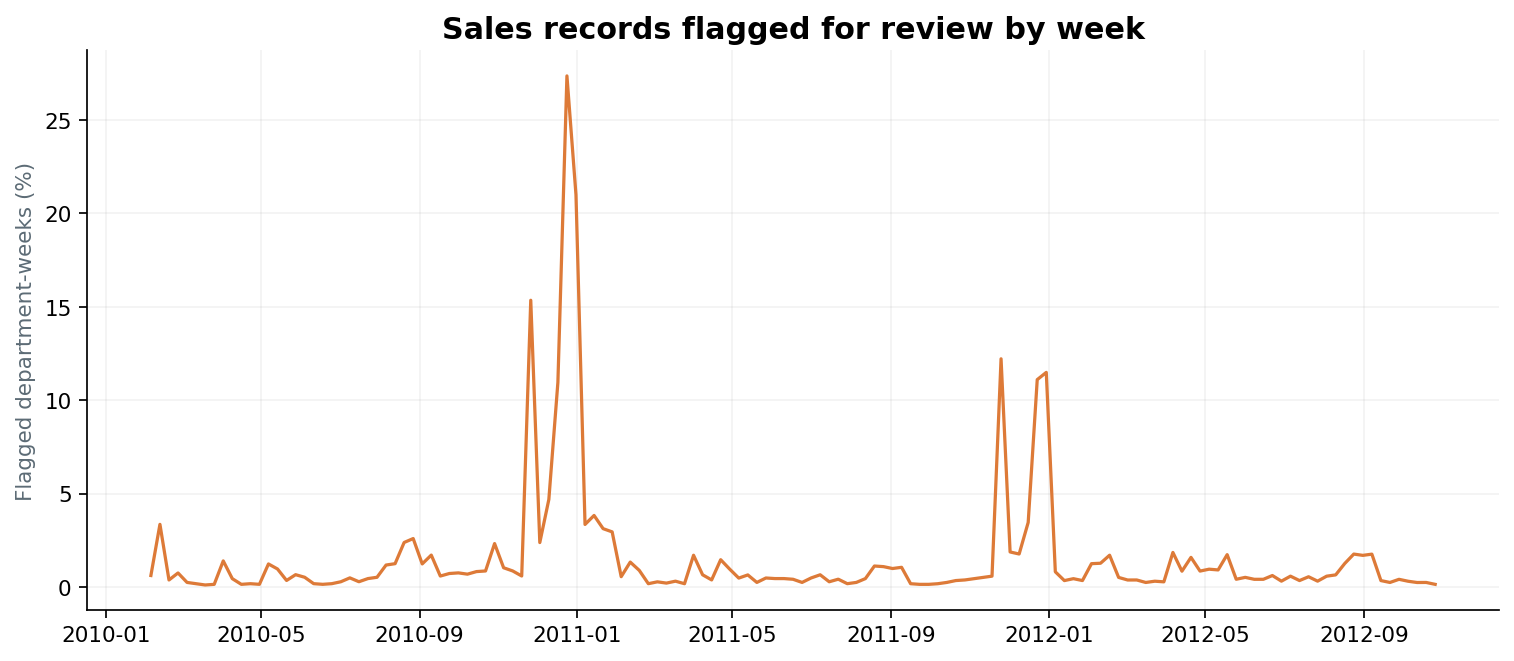

**Why this chart:** Weekly flag rates show changes in investigation workload.

**Observed insight:** 6,618 rows (1.57%) are flagged by either method; flags are not verified errors.

**Business implication and risk:** Investigate promotion and holiday context before changing targets. Automatic removal risks erasing valid demand.

In [40]:
note = chart_notes[16]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 18

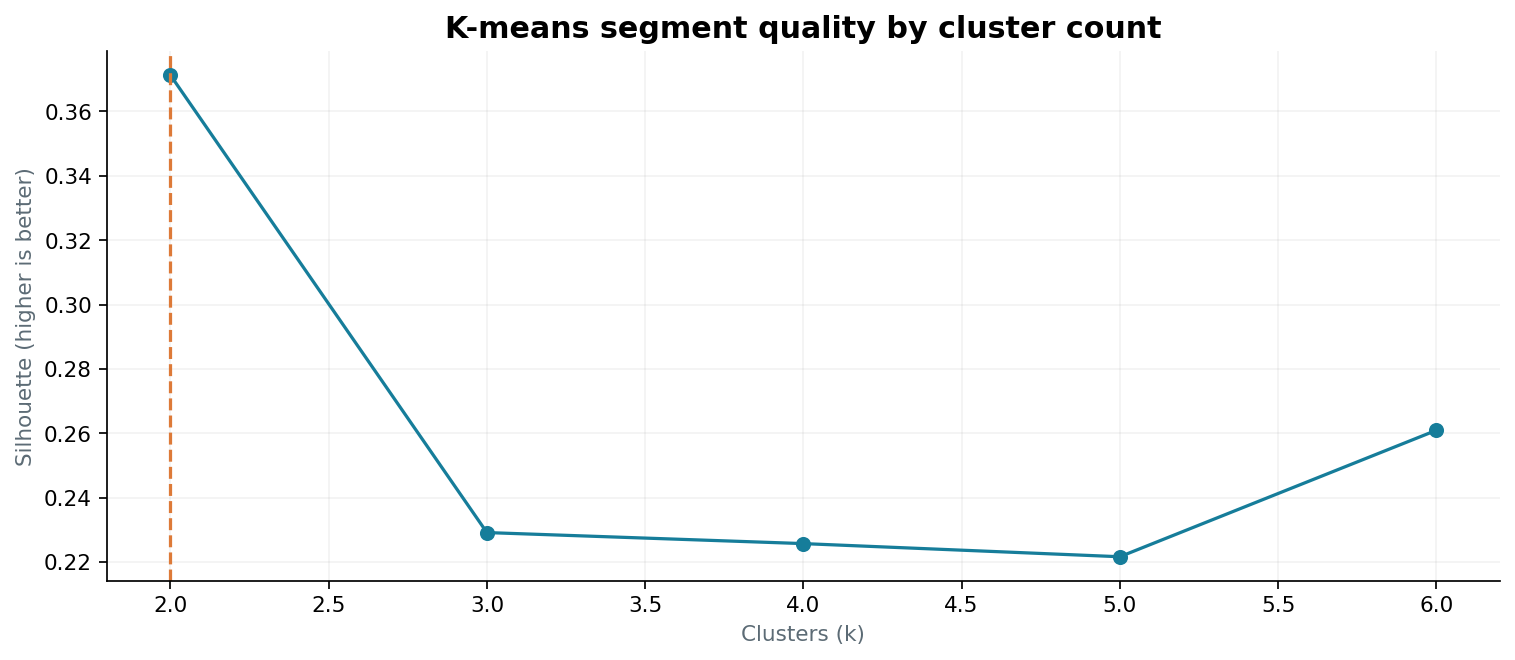

**Why this chart:** A silhouette curve compares within-group cohesion and between-group separation.

**Observed insight:** Selected k=2 with silhouette 0.371; other quality metrics are saved in the tables.

**Business implication and risk:** Treat segments as planning aids. Validate stability and commercial usefulness with store managers.

In [41]:
note = chart_notes[17]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 19

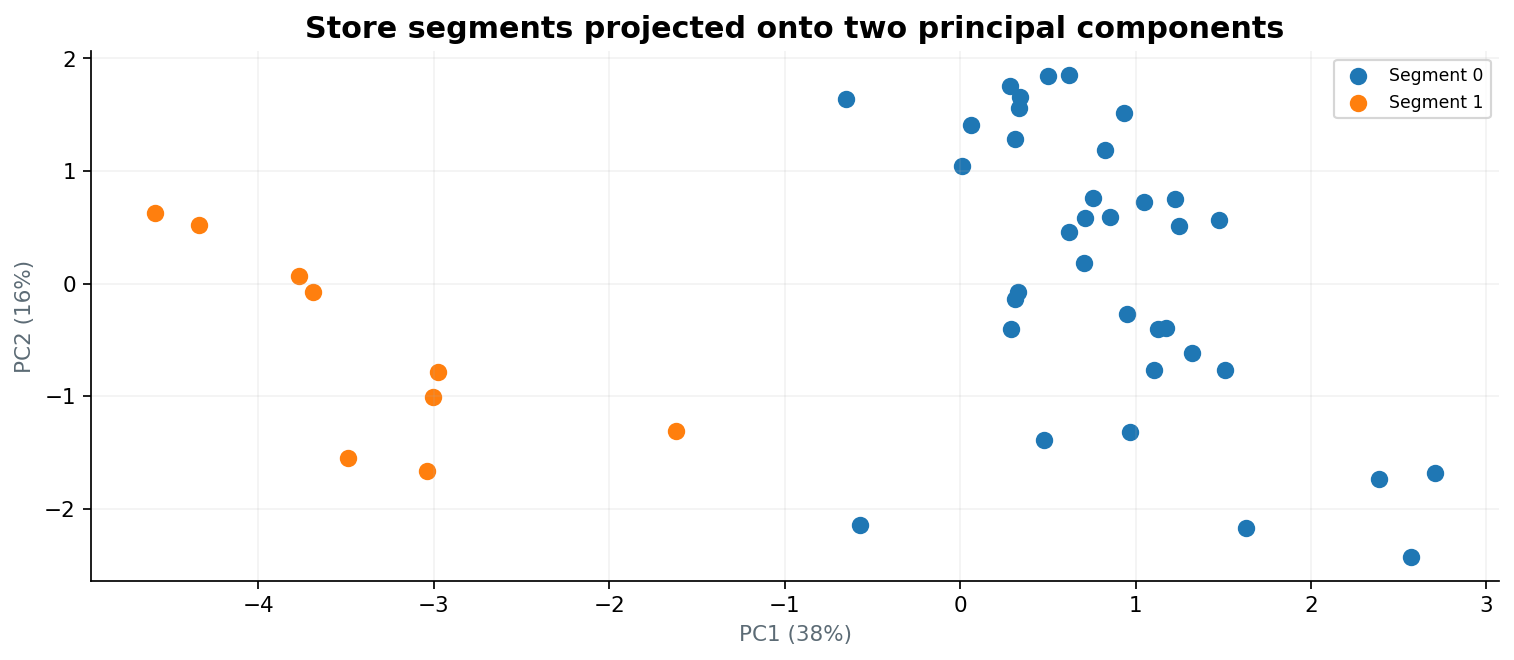

**Why this chart:** PCA gives a compact display of standardized store features; clustering uses the full feature space.

**Observed insight:** Two components explain 54.3% of variance, so the projection does not show all separation.

**Business implication and risk:** Use numeric segment profiles to design campaigns and inventory reviews rather than relying only on a scatterplot.

In [42]:
note = chart_notes[18]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 20

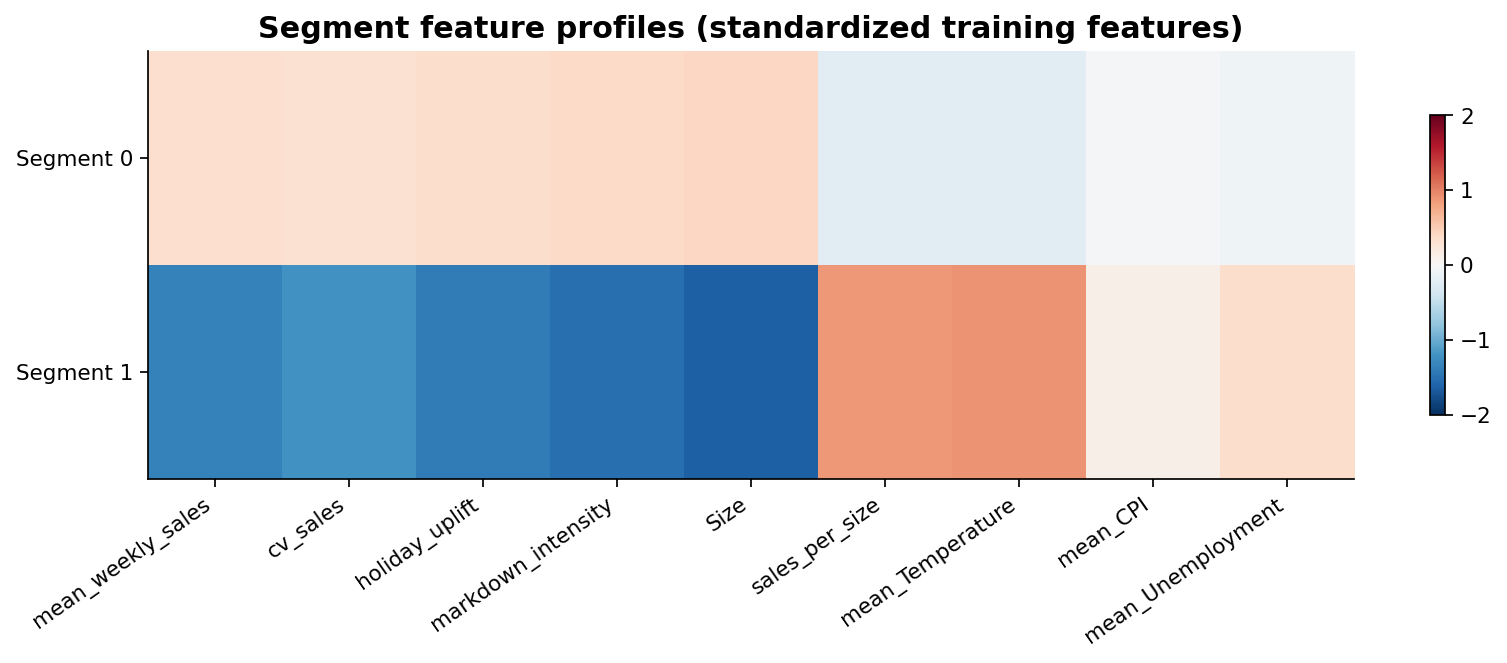

**Why this chart:** A standardized heatmap compares unlike units on a shared scale.

**Observed insight:** Segments differ in scale, efficiency, variability and observed economic/climate context. Location labels are unavailable.

**Business implication and risk:** Tailor store-level planning and promotion pilots; this dataset cannot support individual customer personalization.

In [43]:
note = chart_notes[19]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 21

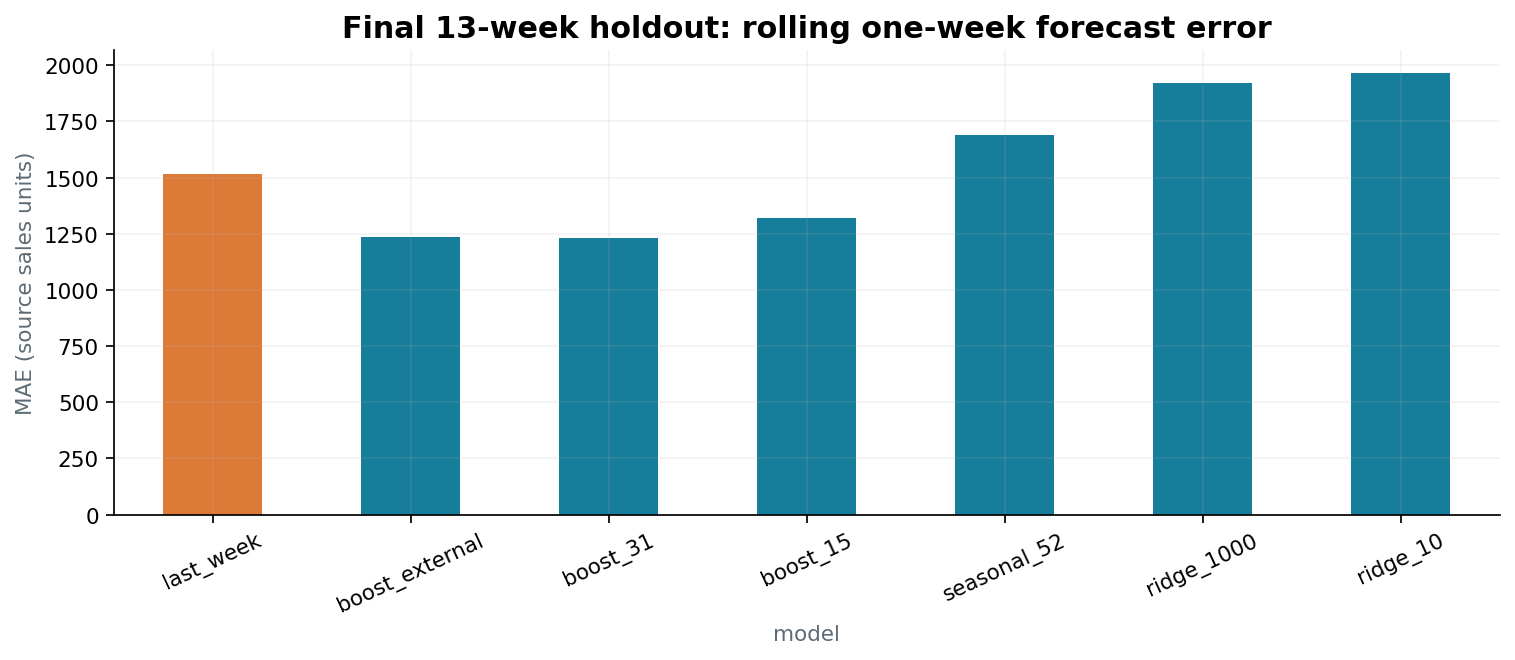

**Why this chart:** A common error scale makes baseline and learned-model performance comparable.

**Observed insight:** The model selected on validation weeks is last_week, with test MAE 1,516.

**Business implication and risk:** Choose on validation, report test once, and monitor errors after deployment. Test ranking must not drive retuning.

In [44]:
note = chart_notes[20]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 22

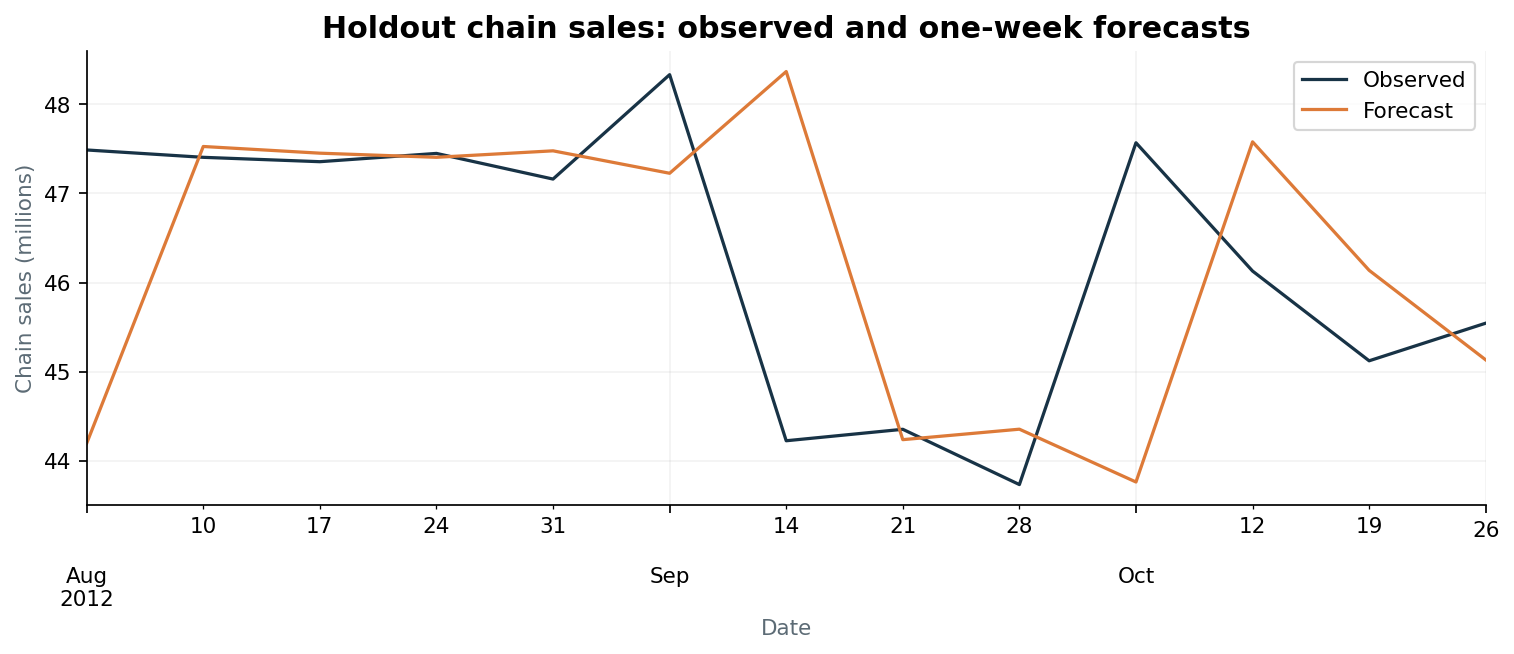

**Why this chart:** A time trace exposes systematic timing errors that average metrics can hide.

**Observed insight:** Chain aggregation can hide offsetting store and department errors; the error tables retain individual predictions.

**Business implication and risk:** Review both chain totals and local errors before replenishment decisions.

In [45]:
note = chart_notes[21]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 23

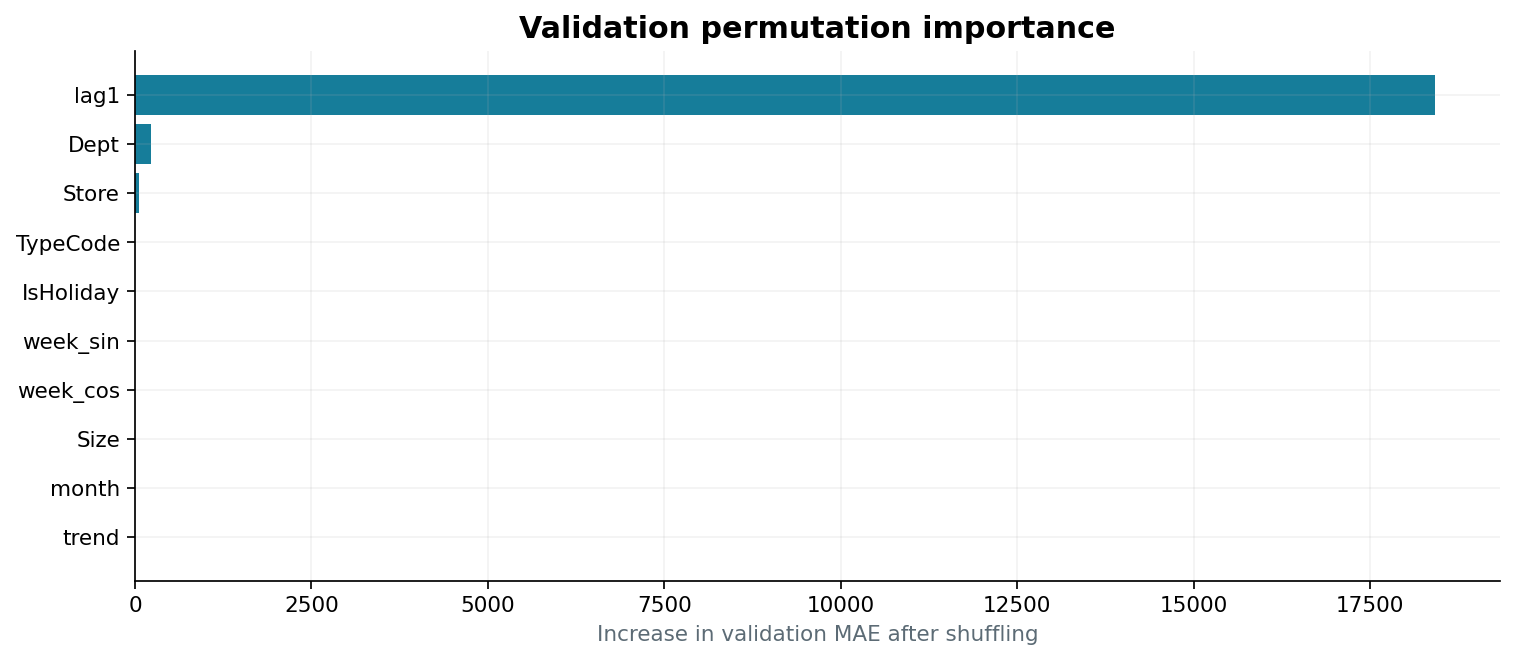

**Why this chart:** Permutation importance measures error increase when a feature is shuffled on validation rows.

**Observed insight:** The largest measured importance is lag1; correlated lags can share importance.

**Business implication and risk:** Use explainability to inspect model dependence. A predictive feature is not necessarily a causal business lever.

In [46]:
note = chart_notes[22]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

### Chart 24

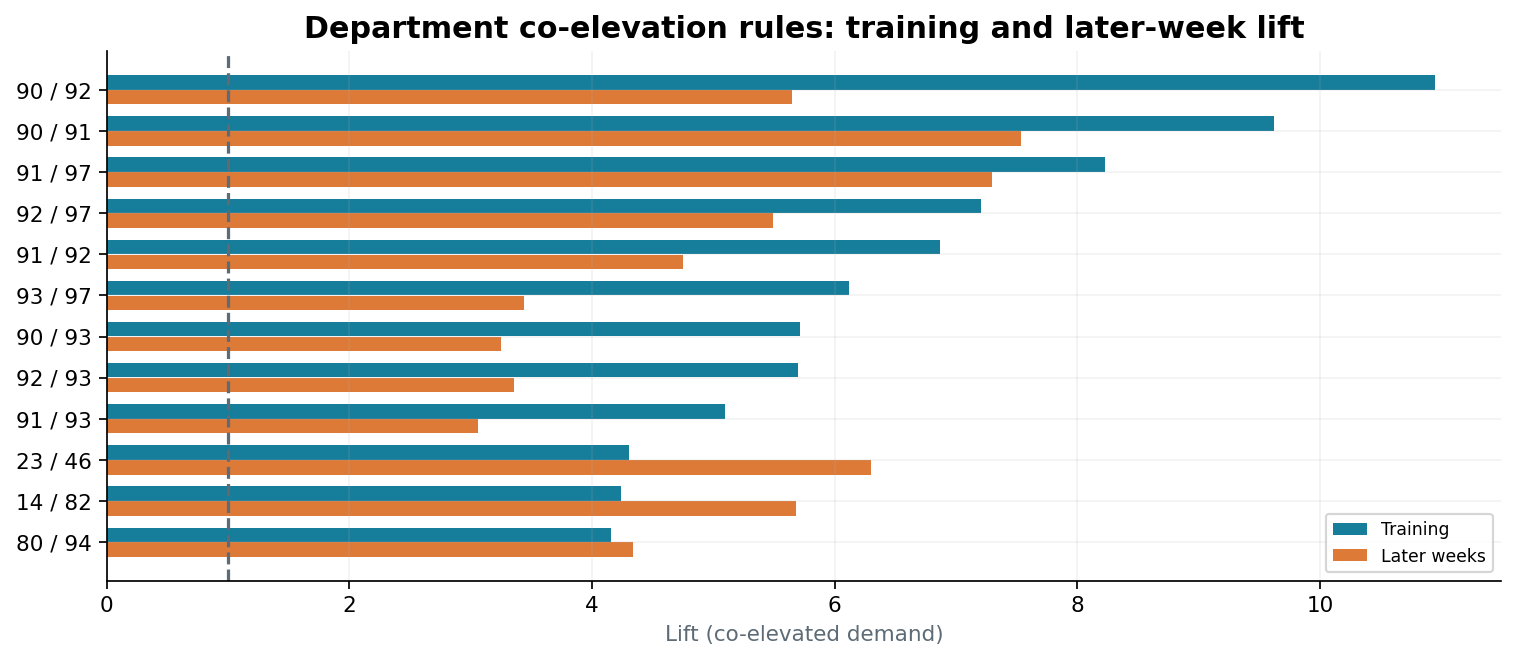

**Why this chart:** Side-by-side lift values reveal whether training co-movement persists later.

**Observed insight:** 803 candidate pairs pass training filters; 548 have later lift above one. No shopper baskets are available.

**Business implication and risk:** Use these pairs for investigation and controlled promotion trials, not claims about items bought together.

In [47]:
note = chart_notes[23]
display(Image(filename=str(OUTPUT_DIR/'charts'/note['file'])))
display(Markdown('**Why this chart:** '+note['why']+'\n\n**Observed insight:** '+note['insight']+'\n\n**Business implication and risk:** '+note['business_impact']))

## 8. Saved Models, Reload Check and Future Work
The held-out evaluation model is saved separately from the model refitted on all historical data. Reloading must reproduce the test predictions. Deployments also need feature availability checks, drift monitoring and a weekly validation process. The serialized models and historical state support future scoring; they do not establish production readiness.

In [48]:
selected = forecast_result['winner']
if selected in forecast_result['models']:
    loaded = joblib.load(OUTPUT_DIR/'models/holdout_forecaster.joblib')
    sample = d.loc[d.Date.ge(test_start)].head(100)
    np.testing.assert_allclose(loaded['model'].predict(sample[loaded['columns']]),
        forecast_result['predictions'][selected].head(100))
    print('Saved model reload reproduces holdout predictions.')
clean = raw.copy()
clean['anomaly_review_flag'] = anomalies.review_flag.to_numpy()
clean.to_csv(OUTPUT_DIR/'tables/cleaned_sales_with_review_flags.csv.gz', index=False, compression='gzip')
joblib.dump({'last_date':d.Date.max(),'series_history':d[KEY+['Date','Weekly_Sales']],
    'store_attributes':stores,'external_history':raw.drop_duplicates(['Store','Date'])[['Store','Date']+EXTERNAL]},
    OUTPUT_DIR/'models/forecast_history.joblib',compress=3)
save_json({'core':CORE,'lagged_external':EXT,'policy':'All external inputs strictly lagged; raw markdown nulls retained.'},
    OUTPUT_DIR/'models/feature_schema.json')
summary = {'data':audit,'selected_model':selected,'test_start':str(test_start.date()),
    'test_end':str(d.Date.max().date()),'selected_test_metrics':forecast_result['scores'].set_index('model').loc[selected].to_dict(),
    'anomalies':anomaly_summary,'segmentation':segments[4],'association_candidates':len(associations),
    'association_test_lift_above_one':int(associations.test_same_direction.sum()),'horizons':horizons.to_dict('records')}
save_json(summary,OUTPUT_DIR/'results.json')
print(json.dumps(summary,indent=2,default=str))


Saved model reload reproduces holdout predictions.
{
  "data": {
    "source_files": {
      "sales data-set.csv": {
        "rows": 421570,
        "columns": [
          "Store",
          "Dept",
          "Date",
          "Weekly_Sales",
          "IsHoliday"
        ],
        "sha256": "74863777ede90605341fb00b6ab34f218fef83fe784adf5330be24b679bd408e",
        "missing": {
          "Store": 0,
          "Dept": 0,
          "Date": 0,
          "Weekly_Sales": 0,
          "IsHoliday": 0
        }
      },
      "Features data set.csv": {
        "rows": 8190,
        "columns": [
          "Store",
          "Date",
          "Temperature",
          "Fuel_Price",
          "MarkDown1",
          "MarkDown2",
          "MarkDown3",
          "MarkDown4",
          "MarkDown5",
          "CPI",
          "Unemployment",
          "IsHoliday"
        ],
        "sha256": "4a95fb9cde1ad7239b52065d2ce578a057a407ef3c49ab2a95bae4253df8ba88",
        "missing": {
          "Store": 0

## Real-world strategy and implementation

1. **Inventory:** pilot forecasts in existing high-volume departments. Translate revenue to units only after adding price, stockout and inventory data. Set safety stock using lead-time forecast error and the desired service level. Review volatile segments more frequently.
2. **Marketing:** tailor store-level calendars and promotion tests to the segment profiles. Evaluate incremental margin, not sales alone. Do not infer individual preferences from store averages.
3. **Cross-selling experiments:** investigate persistent department co-elevation pairs, obtain product mappings and transaction baskets, then run randomized store or time-block trials. Track margin and cannibalization.
4. **Anomaly operations:** prioritize dual-method flags, inspect holiday/markdown/returns context, record reviewer outcomes and approve corrections before retraining. Keep source records and a correction log.
5. **Store optimization:** combine sales per size, variability and forecast bias with margins, capacity and local constraints. A high-volume store is not automatically the most profitable investment.
6. **Rollout:** weeks 1-2 reconcile data and assign owners; weeks 3-4 shadow forecasts; weeks 5-8 run matched-store pilots; weeks 9-12 assess forecast error, stockouts, waste and margin against controls before expanding.

### Challenges and next steps

Limited history, unobserved lost sales, absent units/lead times, changing departments, incomplete markdown reporting and uncertain future economic inputs constrain operating use. Add temporal segment stability checks, verified anomaly labels, probabilistic forecasting and causal promotion trials. Individual personalization requires consented shopper data and transaction history.

## Conclusion

The measured tables and charts above provide the project's findings. Model selection is chronological, all forecasting predictors obey the stated information cutoff, and fixed-origin results distinguish short-term performance from longer planning horizons. Store segmentation supports differentiated planning, while anomaly and association outputs provide investigation queues. The output files are reproducible research artifacts. Business benefit should be measured in a controlled operational pilot.
